# Non-Invasive Diabetes Risk Screening from Behavioural and Demographic Indicators

### A comparative study of classical machine learning and deep neural networks on 253,680 BRFSS records

| | |
|---|---|
| **Student** | Crispin Hebert Hirwa |
| **Course** | Introduction to Machine Learning — Summative Assignment (Final Project) |
| **Institution** | African Leadership University |
| **Term** | 2026 September Term |
| **Report** | `report/Final_Report.pdf` |
| **Dataset** | CDC Diabetes Health Indicators (UCI ML Repository ID 891), DOI [10.24432/C53919](https://doi.org/10.24432/C53919) |

---

## What this notebook does

This notebook builds and evaluates a complete classification workflow that predicts whether an adult respondent
is diabetic or pre-diabetic (`Diabetes_binary = 1`) using **only questionnaire and examination variables** —
no blood test, no laboratory result. That constraint is the entire point of the project: it is what makes
the model deployable in a community clinic that owns a weighing scale and a tape measure but not a laboratory.

The notebook is organised as a single top-to-bottom experiment log. Each section opens with a short
statement of what it does and why, and closes with an interpretation of what the output means.

| Section | Contents |
|---|---|
| 1 | Environment, reproducibility controls, and project paths |
| 2 | Data provenance and integrity audit |
| 3 | Exploratory analysis: imbalance, correlation structure, univariate association |
| 4 | Stratified splitting and leakage-safe preprocessing |
| 5 | Feature engineering and its ablation |
| 6 | Classical experiments E1–E5 (Logistic Regression, Random Forest ×2, Histogram Gradient Boosting, SVM) |
| 7 | Learning curves and bias–variance diagnosis |
| 8 | Deep learning experiments E6–E9 (``tf.data`` pipelines, Sequential and Functional APIs, embeddings, class weighting) |
| 9 | Consolidated evaluation: experiment table, confusion matrices, ROC/PR, error analysis |
| 10 | Model persistence and reproduction instructions |

**All nine experiments are executed on a fixed, stratified 70/15/15 split.** The validation split is used for
early stopping and threshold selection; the test split is touched exactly once, in Section 9.


## 1. Environment and reproducibility controls

Machine learning experiments are only meaningful if they can be repeated. Three things make that hard in
this domain and all three are handled here: unordered hash iteration, an unseeded random number generator,
and an unseeded deep-learning framework.

The cell below fixes a single `SEED` that is propagated to Python's `random`, NumPy, scikit-learn and
TensorFlow/Keras, resolves every project path relative to the repository root (so the notebook survives being
moved, and so it can be run in Colab or any other hosted runtime without a setup step -- if the
`data/raw` directory is not found, the layout is created in the working directory instead of failing), and applies one consistent plotting style so that the figures in the report are byte-identical to the
figures produced here.

Nothing is model-specific in this cell; it is pure infrastructure.


In [1]:
# ----------------------------------------------------------------------------------------------
# Environment, seeds and paths. Run this cell first; every later cell depends on it.
# ----------------------------------------------------------------------------------------------
import os
import sys

# Thread pinning. Set *before* NumPy / scikit-learn / TensorFlow are imported, because OpenMP and
# BLAS read these once at load time.
#   - one thread makes floating-point reductions bit-reproducible, so the numbers in the report
#     survive a rerun on a different machine;
#   - it also keeps every scikit-learn internal `joblib.Parallel` call on its sequential path,
#     which means nothing depends on worker processes being available.
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")    # silence the TF info banner
os.environ.setdefault("TF_ENABLE_ONEDNN_OPTS", "0")   # bit-stable CPU numerics

import json
import time
import random
import hashlib
import platform
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

SEED = 42

# ---- resolve the repository root, creating a working layout if this is a bare runtime ----------
def resolve_project_root() -> Path:
    """Return the repo root, or build the directory layout in the current working directory.

    Running from a clone of the repository finds `data/raw` by walking up the tree. Running in a
    hosted runtime (Colab, Kaggle, a bare Jupyter kernel) has no such directory, so instead of
    failing we create the layout here and let the next cell fetch the data. That is what makes
    "Run all" work with no setup step.
    """
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / "data" / "raw").is_dir():
            return candidate

    for sub in ("data/raw", "figures", "models", "results", "logs/tensorboard", "src"):
        (here / sub).mkdir(parents=True, exist_ok=True)
    print(f"No repository layout found; created one under {here} and will fetch the data next.")
    return here


ROOT = resolve_project_root()

DATA_RAW = ROOT / "data" / "raw" / "diabetes_binary_health_indicators_BRFSS2015.csv"
FIG_DIR = ROOT / "figures"
MODEL_DIR = ROOT / "models"
RESULT_DIR = ROOT / "results"
LOG_DIR = ROOT / "logs"
for _d in (FIG_DIR, MODEL_DIR, RESULT_DIR, LOG_DIR / "tensorboard"):
    _d.mkdir(parents=True, exist_ok=True)

# ---- global seeding ---------------------------------------------------------------------------
def set_global_seed(seed: int = SEED) -> None:
    """Seed every source of randomness used in this notebook."""
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)


set_global_seed()

# ---- plotting ---------------------------------------------------------------------------------
import matplotlib
matplotlib.use("Agg")           # headless: figures are written to disk, not to a window
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep", font_scale=1.0)
plt.rcParams.update({
    "figure.dpi": 130,
    "savefig.dpi": 200,
    "savefig.bbox": "tight",
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
    "font.family": "DejaVu Sans",
})

import sklearn
from sklearn.model_selection import train_test_split, RandomizedSearchCV, learning_curve
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.inspection import permutation_importance
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix, roc_curve,
    precision_recall_curve, matthews_corrcoef, classification_report, brier_score_loss,
)

import tensorflow as tf
import keras
from keras import layers

tf.keras.utils.set_random_seed(SEED)
try:
    tf.config.experimental.enable_op_determinism()   # reproducible TF ops on CPU
except Exception:
    pass

print(f"Python       : {platform.python_version()}")
print(f"NumPy        : {np.__version__}")
print(f"pandas       : {pd.__version__}")
print(f"scikit-learn : {sklearn.__version__}")
print(f"TensorFlow   : {tf.__version__}")
print(f"Keras        : {keras.__version__}")
print(f"Project root : {ROOT}")
print(f"Global seed  : {SEED}")


Python       : 3.12.14
NumPy        : 2.3.5
pandas       : 3.0.1
scikit-learn : 1.9.1
TensorFlow   : 2.21.0
Keras        : 3.15.1
Project root : C:\Users\Hello\Documents\deepseek-harness\default-workspace\ml-summative
Global seed  : 42


## 2. Data provenance and integrity audit

### 2.1 Where the data comes from

The dataset is **CDC Diabetes Health Indicators**, distributed by the UCI Machine Learning Repository as
dataset ID 891 (DOI [10.24432/C53919](https://doi.org/10.24432/C53919)). It is a curated extract of the
**Behavioural Risk Factor Surveillance System (BRFSS) 2015** telephone survey, published by the United
States Centers for Disease Control and Prevention. Each row is one adult respondent; the features are their
answers to the survey plus self-reported height and weight, from which BMI is derived.

It satisfies every constraint of the assignment brief:

| Requirement | Status |
|---|---|
| Original or from an open repository | UCI ML Repository, DOI-minted, publicly downloadable |
| Not a scikit-learn/Keras built-in or toy dataset | Downloaded as a raw CSV from the UCI static host |
| Not synthetic or generated | Real 2015 BRFSS responses, 253,680 respondents |
| ≥ 20,000 raw rows before preprocessing | **253,680 rows** — 12.7× the threshold |
| Categorical target, ≥ 2 classes | `Diabetes_binary` ∈ {0, 1} |

### 2.2 Why this dataset and not a laboratory dataset

The decisive property is that **none of the 21 features is a laboratory measurement.** There is no fasting
glucose, no HbA1c, no oral glucose tolerance test. The strongest predictors available are high blood pressure,
high cholesterol, general health rating and BMI — all obtainable by interview, cuff and scale.

That is not a limitation of the dataset; it is the argument for the project. Glucose-based diagnosis is
out of reach for most primary-care facilities in low- and middle-income countries, where the WHO reports
that laboratory capacity, not clinical intent, is the binding constraint. A model restricted to
questionnaire-and-examination inputs answers a real question: *given only what a rural clinic can collect
in five minutes, how much of the diabetes signal can be recovered, and which modelling paradigm recovers
most of it?*

### 2.3 The integrity audit

`src/download_data.py` fetches the CSV from
`https://archive.ics.uci.edu/static/public/891/data.csv`, verifies its SHA-256 digest and writes it to
`data/raw/`. The cell below does the same thing when the file is absent -- which is the normal case in
Colab -- and then asserts the digest and the row count, so a substituted download stops the run rather
than quietly changing every number downstream. The raw file is **never committed to git** (see `.gitignore`); it is distributed through the
Google Drive folder linked in the report. The cell below re-verifies the digest and prints the audit.


In [2]:
# ----------------------------------------------------------------------------------------------
# Load the raw file and verify it is the file we think it is.
# ----------------------------------------------------------------------------------------------
DATASET_META = {
    "name": "CDC Diabetes Health Indicators",
    "repository": "UCI Machine Learning Repository",
    "dataset_id": 891,
    "doi": "10.24432/C53919",
    "source_url": "https://archive.ics.uci.edu/static/public/891/data.csv",
    "underlying_survey": "CDC Behavioural Risk Factor Surveillance System (BRFSS) 2015",
    "license": "UCI terms of use / CDC public data",
}

def sha256_of(path: Path) -> str:
    """Streaming SHA-256 so a 13 MB file does not need to be held in memory twice."""
    h = hashlib.sha256()
    with open(path, "rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


EXPECTED_SHA256 = "9f71fda9d4ae5f4878c99b9233b6a16accfa9a17c194116a6b78100540934964"
EXPECTED_ROWS = 253_680


if not DATA_RAW.exists():
    # Hosted runtimes start empty. Fetch from the UCI static host rather than failing, then verify.
    import ssl
    import urllib.request

    DATA_RAW.parent.mkdir(parents=True, exist_ok=True)
    print(f"Raw file absent -- downloading {DATASET_META['source_url']}")
    with urllib.request.urlopen(DATASET_META["source_url"],
                                context=ssl.create_default_context(), timeout=300) as response:
        DATA_RAW.write_bytes(response.read())
    print(f"Downloaded {DATA_RAW.stat().st_size/1e6:.2f} MB to {DATA_RAW}")

RAW_SHA256 = sha256_of(DATA_RAW)
assert RAW_SHA256 == EXPECTED_SHA256, (
    f"Digest mismatch: expected {EXPECTED_SHA256}, got {RAW_SHA256}. The file is not the dataset "
    f"this study used, so every number downstream would be wrong."
)

raw = pd.read_csv(DATA_RAW)
assert len(raw) == EXPECTED_ROWS, f"Expected {EXPECTED_ROWS:,} rows, found {len(raw):,}"

print("File      :", DATA_RAW.name)
print("Size      :", f"{DATA_RAW.stat().st_size/1e6:.2f} MB")
print("SHA-256   :", RAW_SHA256)
print("Shape     :", f"{raw.shape[0]:,} rows x {raw.shape[1]} columns")
print()
print("Columns   :")
print(", ".join(raw.columns))


File      : diabetes_binary_health_indicators_BRFSS2015.csv
Size      : 13.49 MB
SHA-256   : 9f71fda9d4ae5f4878c99b9233b6a16accfa9a17c194116a6b78100540934964
Shape     : 253,680 rows x 23 columns

Columns   :
ID, Diabetes_binary, HighBP, HighChol, CholCheck, BMI, Smoker, Stroke, HeartDiseaseorAttack, PhysActivity, Fruits, Veggies, HvyAlcoholConsump, AnyHealthcare, NoDocbcCost, GenHlth, MentHlth, PhysHlth, DiffWalk, Sex, Age, Education, Income


### 2.4 Structural audit

Before any model sees this table, four things must be established: whether values are missing, whether rows
are duplicated, whether any column is constant (and therefore useless), and whether every value falls inside
the coding scheme the data dictionary specifies. A value of `GenHlth = 7` when the scale runs 1–5 would be a
data-entry error, and an error of that kind silently poisons a distance-based model.

The checks are cheap and they are the difference between a pipeline that is defensible and one that
merely produces a number.

One outcome of the audit needs flagging before it is reached, because it shapes the interpretation of
every result that follows. The dataset contains **no missing values and no exact duplicate rows**, but it
does contain repeated *response profiles*: 25,772 rows are repeats of another row's 21 answers, and 1,566 of
those profile groups carry **both** labels. Two respondents who answer all 21 questions identically and still
differ on diagnosis are not a data-entry error — they are two different people, and no model restricted to
these 21 features can separate them. The audit quantifies that set: it is the **irreducible error floor** of
the task, and it caps achievable accuracy from above regardless of model depth.

This is measured rather than assumed, and Section 8's A9 run tests whether it matters in practice by
refitting the best classical configuration on a de-duplicated cohort.

**Table I** (written to `results/table1_dataset_summary.csv`) is the variable dictionary used in the report;
it is generated from the code rather than typed by hand so the two can never drift apart.


In [3]:
# ----------------------------------------------------------------------------------------------
# Integrity audit: missingness, duplication, constant columns, and domain validity.
# ----------------------------------------------------------------------------------------------
TARGET = "Diabetes_binary"
ID_COL = "ID"

# Coding scheme taken from the UCI data dictionary for dataset 891.
VARIABLE_SPEC = {
    "HighBP":              ("binary",  "High blood pressure, self-reported",            {0, 1}),
    "HighChol":            ("binary",  "High cholesterol, self-reported",                {0, 1}),
    "CholCheck":           ("binary",  "Cholesterol check in past 5 years",              {0, 1}),
    "BMI":                 ("integer", "Body mass index (kg/m^2)",                       None),
    "Smoker":              ("binary",  "Smoked >=100 cigarettes in lifetime",            {0, 1}),
    "Stroke":              ("binary",  "Ever told had a stroke",                         {0, 1}),
    "HeartDiseaseorAttack":("binary",  "Coronary heart disease or myocardial infarction",{0, 1}),
    "PhysActivity":        ("binary",  "Physical activity in past 30 days (not job)",    {0, 1}),
    "Fruits":              ("binary",  "Consumes fruit >=1 time per day",                {0, 1}),
    "Veggies":             ("binary",  "Consumes vegetables >=1 time per day",           {0, 1}),
    "HvyAlcoholConsump":   ("binary",  "Heavy alcohol consumption",                      {0, 1}),
    "AnyHealthcare":       ("binary",  "Has any health coverage",                        {0, 1}),
    "NoDocbcCost":         ("binary",  "Could not see doctor in past 12 months (cost)",  {0, 1}),
    "GenHlth":             ("ordinal", "General health, 1=excellent .. 5=poor",          {1, 2, 3, 4, 5}),
    "MentHlth":            ("integer", "Days mental health not good (0-30)",             None),
    "PhysHlth":            ("integer", "Days physical health not good (0-30)",           None),
    "DiffWalk":            ("binary",  "Difficulty walking or climbing stairs",          {0, 1}),
    "Sex":                 ("binary",  "Sex, 0=female 1=male",                           {0, 1}),
    "Age":                 ("ordinal", "13-level age category, 1=18-24 .. 13=80+",       set(range(1, 14))),
    "Education":           ("ordinal", "1=never attended .. 6=college graduate",         set(range(1, 7))),
    "Income":              ("ordinal", "1=<$10k .. 8=>=$75k",                            set(range(1, 9))),
}

FEATURES = [c for c in raw.columns if c not in (ID_COL, TARGET)]

# ---- check 1: missing values ---------------------------------------------------------------
missing = raw.isna().sum()
n_missing_total = int(missing.sum())

# ---- check 2: exact duplicate rows ---------------------------------------------------------
n_dup_rows = int(raw.duplicated().sum())
n_dup_features = int(raw.drop(columns=[ID_COL]).duplicated().sum())

# ---- check 3: constant columns -------------------------------------------------------------
constant_cols = [c for c in raw.columns if raw[c].nunique() <= 1]

# ---- check 4: domain validity --------------------------------------------------------------
domain_violations = {}
for col, (_, _, allowed) in VARIABLE_SPEC.items():
    if allowed is None:
        continue
    bad = set(raw[col].unique()) - allowed
    if bad:
        domain_violations[col] = sorted(bad)

print("=" * 78)
print("INTEGRITY AUDIT")
print("=" * 78)
print(f"Rows                                  : {len(raw):,}")
print(f"Columns (incl. ID and target)         : {raw.shape[1]}")
print(f"Missing cells (total)                 : {n_missing_total}")
print(f"Rows with >=1 missing cell            : {int(raw.isna().any(axis=1).sum()):,}")
print(f"Exact duplicate rows                  : {n_dup_rows:,}")
print(f"Duplicate rows ignoring ID            : {n_dup_features:,}")
print(f"Constant columns                      : {constant_cols if constant_cols else 'none'}")
print(f"Domain violations                     : {domain_violations if domain_violations else 'none'}")
print(f"Unique IDs / rows                     : {raw[ID_COL].nunique():,} / {len(raw):,}")
print()
print("Physical range of every feature:")
rng = pd.DataFrame({
    "min": raw[FEATURES].min(),
    "max": raw[FEATURES].max(),
    "n_unique": raw[FEATURES].nunique(),
}).T
print(rng.to_string())

# The audit is an assertion, not a narrative: if any of these fail the notebook stops here.
assert n_missing_total == 0, "Unexpected missing values"
assert n_dup_rows == 0, "Unexpected duplicate rows"
assert not constant_cols, "Constant column present"
assert not domain_violations, "Out-of-range coded value present"
print("\nAll integrity assertions passed.")

# ---- check 5: duplicated *response profiles* and whether they agree on the label ----------------
# Two respondents who answer all 21 questions identically are not an error -- they are two different
# people who happen to give the same answers.  But if such a profile carries both labels, no model
# using these 21 features can separate them: that is an irreducible error floor, and it is worth
# measuring rather than discovering later.
profile = raw.groupby(FEATURES, sort=False, dropna=False)["Diabetes_binary"]
group_size = profile.size()
group_label_count = profile.nunique()
conflicting_groups = group_label_count[group_label_count > 1]

n_profiles = len(group_size)
n_multi = int((group_size > 1).sum())
n_conflict_groups = len(conflicting_groups)
n_conflict_rows = int(group_size.loc[conflicting_groups.index].sum())
dedup_prevalence = float(raw.drop_duplicates(subset=FEATURES, keep="first")[TARGET].mean())

print()
print("DUPLICATE RESPONSE PROFILES")
print(f"Distinct response profiles            : {n_profiles:,}")
print(f"Rows that are repeats of an earlier row: {len(raw) - n_profiles:,} "
      f"({(len(raw)-n_profiles)/len(raw):.2%} of the cohort)")
print(f"Profiles occurring more than once     : {n_multi:,}  (largest repeats {int(group_size.max())} times)")
print(f"Profiles carrying BOTH labels         : {n_conflict_groups:,} "
      f"({n_conflict_groups/n_multi:.1%} of repeated profiles)")
print(f"Rows sitting in a label-conflicting profile: {n_conflict_rows:,} "
      f"({n_conflict_rows/len(raw):.2%} of the cohort)")
print(f"Prevalence  raw {raw[TARGET].mean():.4f}  vs  de-duplicated {dedup_prevalence:.4f}")
print()
print(f"Interpretation: at most {n_conflict_rows/len(raw):.2%} of the cohort is unlearnable from these")
print("features alone. That is the noise floor of the task, not a defect of the model --")
print("and it bounds achievable accuracy from above no matter how deep the network is.")


INTEGRITY AUDIT
Rows                                  : 253,680
Columns (incl. ID and target)         : 23
Missing cells (total)                 : 0
Rows with >=1 missing cell            : 0
Exact duplicate rows                  : 0
Duplicate rows ignoring ID            : 24,206
Constant columns                      : none
Domain violations                     : none
Unique IDs / rows                     : 253,680 / 253,680

Physical range of every feature:
          HighBP  HighChol  CholCheck  BMI  Smoker  Stroke  HeartDiseaseorAttack  PhysActivity  Fruits  Veggies  HvyAlcoholConsump  AnyHealthcare  NoDocbcCost  GenHlth  MentHlth  PhysHlth  DiffWalk  Sex  Age  Education  Income
min            0         0          0   12       0       0                     0             0       0        0                  0              0            0        1         0         0         0    0    1          1       1
max            1         1          1   98       1       1                     1    

### 2.5 The variable dictionary and the class imbalance

**Table I** below is the dictionary the report cites. It is generated programmatically from `VARIABLE_SPEC`
so that the report table and the notebook cannot disagree.

**Figure 1** quantifies the problem the rest of the notebook has to solve. 86.07 % of respondents are
non-diabetic and 13.93 % are diabetic or pre-diabetic — a ratio of roughly 6.2 to 1. Two consequences follow
immediately and they shape every design decision that comes after this cell:

1. **Accuracy is a misleading headline metric.** A model that predicts "no diabetes" for every respondent
   scores 0.8607 accuracy while detecting nobody. The classifier that achieves it has learned nothing and
   would be worthless clinically, yet it would top an accuracy-only leaderboard. Every model in this study is
   therefore evaluated on **ROC-AUC, PR-AUC, recall and F1** alongside accuracy.
2. **The default decision threshold is not the right threshold.** At 0.5, a model trained on 6:1 data
   systematically under-predicts the minority class. Section 9.4 shows what happens when the threshold is
   chosen on the validation split instead of assumed.


Table I written to results/table1_dataset_summary.csv
            Variable    Type                                     Description Values      Mean    Role
              HighBP  binary              High blood pressure, self-reported    0-1  0.429001 Feature
            HighChol  binary                 High cholesterol, self-reported    0-1  0.424121 Feature
           CholCheck  binary               Cholesterol check in past 5 years    0-1  0.962670 Feature
                 BMI integer                        Body mass index (kg/m^2)  12-98 28.382364 Feature
              Smoker  binary             Smoked >=100 cigarettes in lifetime    0-1  0.443169 Feature
              Stroke  binary                          Ever told had a stroke    0-1  0.040571 Feature
HeartDiseaseorAttack  binary Coronary heart disease or myocardial infarction    0-1  0.094186 Feature
        PhysActivity  binary     Physical activity in past 30 days (not job)    0-1  0.756544 Feature
              Fruits  binary

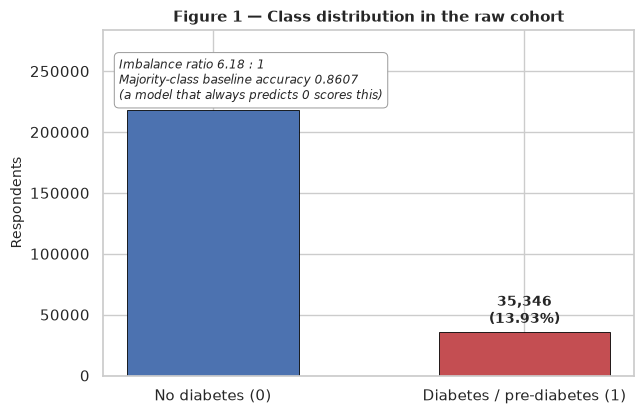

In [4]:
# ----------------------------------------------------------------------------------------------
# Table I (variable dictionary) and Figure 1 (class distribution).
# ----------------------------------------------------------------------------------------------
table1 = pd.DataFrame([
    {
        "Variable": var,
        "Type": typ,
        "Description": desc,
        "Values": (f"{sorted(allowed)[0]}-{sorted(allowed)[-1]}"
                   if allowed is not None else f"{raw[var].min()}-{raw[var].max()}"),
        "Mean": float(raw[var].mean()),
        "Role": "Target" if var == TARGET else "Feature",
    }
    for var, (typ, desc, allowed) in VARIABLE_SPEC.items()
])
table1.to_csv(RESULT_DIR / "table1_dataset_summary.csv", index=False)
print("Table I written to results/table1_dataset_summary.csv")
print(table1.to_string(index=False))

# ---- class balance ----------------------------------------------------------------------------
counts = raw[TARGET].value_counts().sort_index()
prev = raw[TARGET].mean()
labels = ["No diabetes (0)", "Diabetes / pre-diabetes (1)"]
colors = ["#4C72B0", "#C44E52"]

fig, ax = plt.subplots(figsize=(6.6, 4.3))

bars = ax.bar(labels, counts.values, color=colors, width=0.55, edgecolor="black", linewidth=0.6)
for bar, c in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, c + 4000, f"{c:,}\n({c/len(raw):.2%})",
            ha="center", va="bottom", fontsize=10, fontweight="bold")
ax.set_ylabel("Respondents")
ax.set_ylim(0, counts.max() * 1.30)
ax.set_title("Figure 1 — Class distribution in the raw cohort")
ax.annotate(
    f"Imbalance ratio {counts[0]/counts[1]:.2f} : 1\n"
    f"Majority-class baseline accuracy {max(prev, 1-prev):.4f}\n"
    f"(a model that always predicts 0 scores this)",
    xy=(0.03, 0.80), xycoords="axes fraction", fontsize=8.5, style="italic",
    bbox={"boxstyle": "round,pad=0.4", "facecolor": "white", "edgecolor": "0.6", "linewidth": 0.7},
)

fig.tight_layout()
fig.savefig(FIG_DIR / "fig1_class_distribution.png")
print(f"\nPositive prevalence          : {prev:.4f} ({prev:.2%})")
print(f"Imbalance ratio              : {counts[0]/counts[1]:.2f} : 1")
print(f"Majority-class-only accuracy : {max(prev, 1-prev):.4f}   <-- the floor any useful model must clear")


## 3. Exploratory analysis: what actually carries signal

Exploratory analysis here has one job — to decide, on evidence rather than intuition, which features deserve
engineering effort and which are probably noise. Two questions are asked:

**Question 1 (Figure 2): which features are redundant with each other?**
Binary and ordinal variables make Pearson's *r* an unreliable summary, so Spearman's rank correlation is
used throughout. Rank correlation is invariant to any monotone rescaling, which matters because `Income`,
`Education` and `Age` are coded as ordered bands rather than measured quantities — the gap between band 1
and band 2 is not a constant number of dollars, so treating them as interval data would be an assumption
dressed up as a measurement.

**Question 2 (Figure 3): which features carry information about the target *on their own*?**
Two complementary screens are computed. **Spearman's ρ** captures monotone association, which suits ordered
predictors, but it can only detect relationships that are monotone. **Mutual information** captures any
dependence, monotone or not, which is exactly what a tree ensemble or a neural network can exploit. Where the
two disagree, non-monotone structure is present — and that is a direct argument for the engineered features
introduced in Section 5.


Strongest inter-feature associations (Spearman):
        a        b    rho
Education   Income +0.452
  GenHlth PhysHlth +0.452
 DiffWalk  GenHlth +0.423
 DiffWalk PhysHlth +0.415
  GenHlth   Income -0.354
      Age   HighBP +0.345

Feature ranking by mutual information (top 12):
             feature  mutual_info  spearman_rho
             GenHlth       0.0446        0.2877
              HighBP       0.0360        0.2631
                 BMI       0.0280        0.2263
            HighChol       0.0223        0.2003
                 Age       0.0204        0.1777
            DiffWalk       0.0182        0.2183
              Income       0.0140       -0.1633
            PhysHlth       0.0136        0.1568
HeartDiseaseorAttack       0.0120        0.1773
           Education       0.0079       -0.1200
        PhysActivity       0.0068       -0.1181
              Stroke       0.0038        0.1058

Weakest six features by mutual information: Smoker, Veggies, Fruits, NoDocbcCost, Sex, AnyHealt

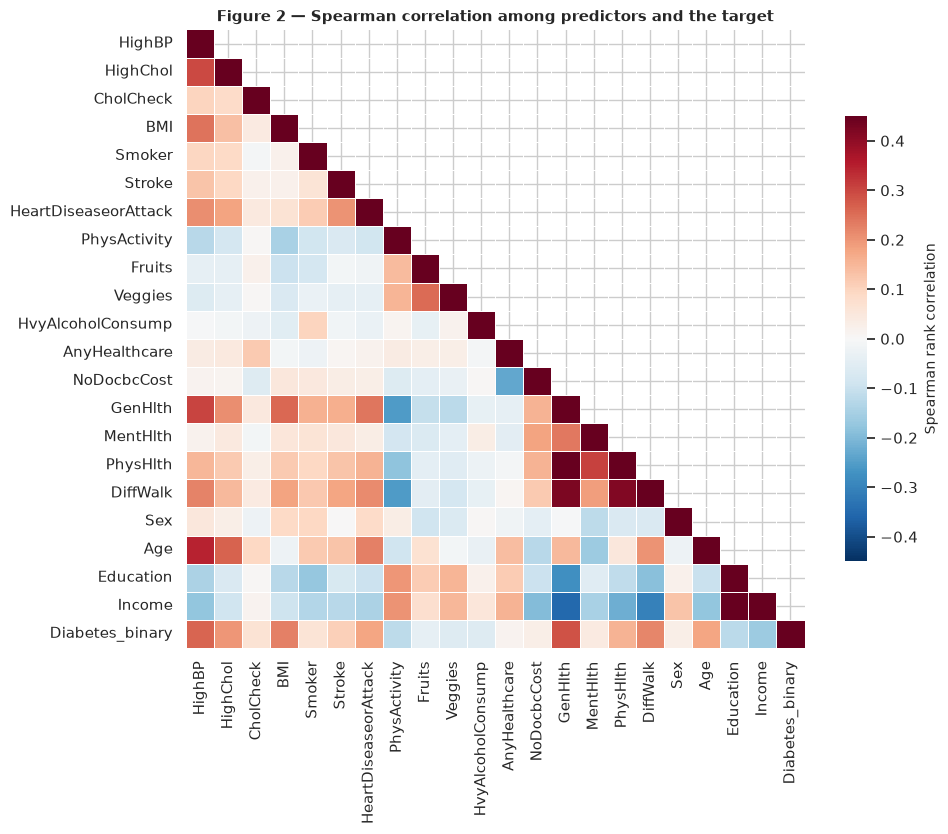

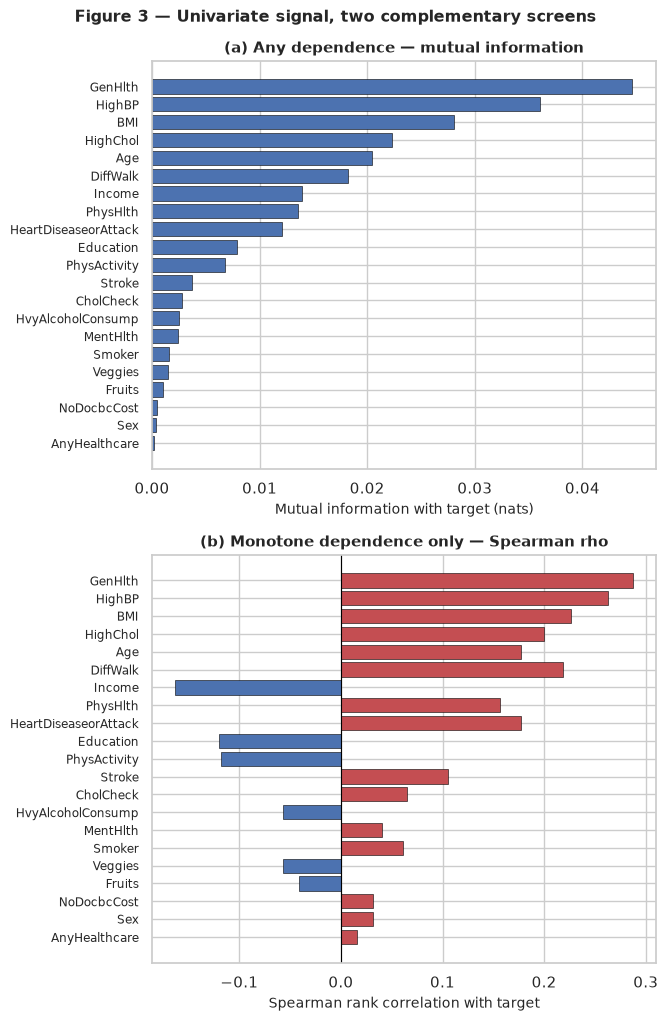

In [5]:
# ----------------------------------------------------------------------------------------------
# Figure 2: Spearman correlation structure.  Figure 3: univariate signal per feature.
# ----------------------------------------------------------------------------------------------
corr_cols = FEATURES + [TARGET]
spearman = raw[corr_cols].corr(method="spearman")

fig, ax = plt.subplots(figsize=(10.2, 8.4))
mask = np.triu(np.ones_like(spearman, dtype=bool), k=1)
sns.heatmap(
    spearman, mask=mask, cmap="RdBu_r", center=0, vmin=-0.45, vmax=0.45,
    square=True, linewidths=0.4, linecolor="white", ax=ax,
    cbar_kws={"shrink": 0.72, "label": "Spearman rank correlation"},
    annot=False,
)
ax.set_title("Figure 2 — Spearman correlation among predictors and the target")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig2_correlation_heatmap.png")
# ---- strongest off-diagonal feature pairs -----------------------------------------------------
pairs = (
    spearman.loc[FEATURES, FEATURES]
    .where(~np.eye(len(FEATURES), dtype=bool))
    .stack()
    .rename("rho")
    .reset_index()
    .rename(columns={"level_0": "a", "level_1": "b"})
)
pairs["abs_rho"] = pairs["rho"].abs()
pairs = pairs[pairs["a"] < pairs["b"]].sort_values("abs_rho", ascending=False).head(6)
print("Strongest inter-feature associations (Spearman):")
print(pairs[["a", "b", "rho"]].to_string(index=False, float_format=lambda x: f"{x:+.3f}"))

# ---- univariate association with the target ---------------------------------------------------
# Mutual information needs a manageable sample; 40k rows gives a stable estimate and runs in seconds.
mi_sample = raw.sample(n=40_000, random_state=SEED)
mi = mutual_info_classif(
    mi_sample[FEATURES], mi_sample[TARGET],
    discrete_features=True, n_neighbors=3, random_state=SEED,
)
assoc = pd.DataFrame({
    "feature": FEATURES,
    "mutual_info": mi,
    "spearman_rho": [spearman.loc[f, TARGET] for f in FEATURES],
})
assoc["abs_rho"] = assoc["spearman_rho"].abs()
assoc = assoc.sort_values("mutual_info", ascending=False).reset_index(drop=True)
assoc.to_csv(RESULT_DIR / "feature_association.csv", index=False)

fig, axes = plt.subplots(2, 1, figsize=(6.8, 10.4))
shown = assoc.iloc[::-1]

axes[0].barh(shown["feature"], shown["mutual_info"], color="#4C72B0", edgecolor="black", linewidth=0.4)
axes[0].set_xlabel("Mutual information with target (nats)")
axes[0].set_title("(a) Any dependence — mutual information")
axes[0].tick_params(axis="y", labelsize=8.5)

colors = ["#C44E52" if r > 0 else "#4C72B0" for r in shown["spearman_rho"]]
axes[1].barh(shown["feature"], shown["spearman_rho"], color=colors, edgecolor="black", linewidth=0.4)
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set_xlabel("Spearman rank correlation with target")
axes[1].set_title("(b) Monotone dependence only — Spearman rho")
axes[1].tick_params(axis="y", labelsize=8.5)

fig.suptitle("Figure 3 — Univariate signal, two complementary screens", fontsize=11.5, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig3_feature_association.png")
print("\nFeature ranking by mutual information (top 12):")
print(assoc.head(12)[["feature", "mutual_info", "spearman_rho"]]
      .to_string(index=False, float_format=lambda x: f"{x:.4f}"))

weaker = assoc.tail(6)["feature"].tolist()
print(f"\nWeakest six features by mutual information: {', '.join(weaker)}")
print("These are candidates for the redundancy analysis in Section 9.6, not for automatic deletion:")
print("a feature can be weak alone and useful in interaction.")


## 4. Splitting: three disjoint partitions, stratified

The split is **70 / 15 / 15** and it is asserted, not assumed, because every result in this notebook depends
on it being exactly this.

The three-way split exists for a specific reason. With two partitions one is forced to choose between using
the held-out data to early-stop a network — which leaks it — or not early-stopping at all. A validation split
resolves that: **early stopping, hyperparameter selection and threshold tuning all happen on `val`**, and
`test` is evaluated once, in Section 9, after every model is frozen.

Stratification preserves the 13.93 % prevalence in all three partitions. Without it, random chance would move
the positive rate by roughly ±0.35 percentage points per partition, and a comparison between two models
scoring within a point of each other would be measuring split noise rather than model quality.

The `ID` column is dropped before splitting. It is a row index, not a measurement; leaving it in would allow a
model to memorise respondents and would trivially inflate any tree model that split on it.


In [6]:
# ----------------------------------------------------------------------------------------------
# Stratified 70/15/15 split.  Train -> fit.  Validation -> early stopping, tuning, threshold.
# Test -> touched once, in Section 9.
# ----------------------------------------------------------------------------------------------
X_all = raw[FEATURES].copy()
y_all = raw[TARGET].astype(int).copy()

X_train, X_hold, y_train, y_hold = train_test_split(
    X_all, y_all, test_size=0.30, stratify=y_all, random_state=SEED
)
X_val, X_test, y_val, y_test = train_test_split(
    X_hold, y_hold, test_size=0.50, stratify=y_hold, random_state=SEED
)

split_summary = pd.DataFrame({
    "partition": ["train", "validation", "test"],
    "rows": [len(X_train), len(X_val), len(X_test)],
    "share": [len(X_train) / len(X_all), len(X_val) / len(X_all), len(X_test) / len(X_all)],
    "positives": [int(y_train.sum()), int(y_val.sum()), int(y_test.sum())],
    "prevalence": [y_train.mean(), y_val.mean(), y_test.mean()],
})
print(split_summary.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

# ---- assertions: the split must be exactly what the report claims ------------------------------
assert len(X_train) + len(X_val) + len(X_test) == len(X_all)
assert len(set(X_train.index) & set(X_val.index)) == 0
assert len(set(X_train.index) & set(X_test.index)) == 0
assert len(set(X_val.index) & set(X_test.index)) == 0
for s in split_summary["prevalence"]:
    assert abs(s - y_all.mean()) < 0.002, "stratification drifted"
print("\nPartitions are disjoint, exhaustive and equally stratified.")


 partition   rows  share  positives  prevalence
     train 177576 0.7000      24742      0.1393
validation  38052 0.1500       5302      0.1393
      test  38052 0.1500       5302      0.1393

Partitions are disjoint, exhaustive and equally stratified.


## 5. Feature engineering

### 5.1 The reasoning

Figure 3 showed that the fifteen binary indicators are individually weak: none exceeds ρ = 0.28 with the
target, and most sit below 0.10. That is expected. Diabetes is a syndrome, not a symptom — it emerges from the
*co-occurrence* of adiposity, hypertension, dyslipidaemia, inactivity and age. A logistic regression cannot
discover such co-occurrence on its own, and a tree can only discover it by spending splits on axis-aligned
thresholds, which is expensive in a 21-dimensional space where each split must be justified by a variance
reduction.

The engineered features below therefore **encode clinical prior knowledge explicitly** rather than hoping the
model stumbles on it. Nine features are added, each traceable to a published clinical or epidemiological
construct. None of them uses the target, so none can leak.

| Engineered feature | Definition | Clinical justification |
|---|---|---|
| `BMI_band` | WHO category: <18.5, 18.5–24.9, 25–29.9, 30–34.9, 35–39.9, ≥40 | Diabetes risk is not linear in BMI; it steps up at the overweight (25) and obesity (30) cut-points, so a categorical band exposes a threshold the raw integer hides |
| `CardioRisk` | Count of {HighBP, HighChol, Stroke, HeartDisease, DiffWalk} ∈ 0–5 | Metabolic syndrome clusters; cumulative burden is more informative than any single indicator |
| `HealthyBehaviour` | Count of {physically active, eats fruit, eats vegetables, non-smoker, no heavy drinking} ∈ 0–5 | Behavioural risk factors cluster in the same individuals; composite lifestyle scores are standard in BRFSS analyses |
| `CareAccess` | AnyHealthcare + CholCheck + (1 − NoDocbcCost) ∈ 0–3 | Access to care drives the *probability of being diagnosed*, a documented source of detection bias in survey data |
| `PoorHealthDays` | MentHlth + PhysHlth ∈ 0–60 | Total unhealthy days is a validated single-item comorbidity proxy |
| `FrequentPoorDays` | 1 if either MentHlth or PhysHlth ≥ 14 | Fourteen days is the conventional clinical cut-point that defines "frequent" poor health |
| `AgeBMI` | Age band × BMI | Adiposity carries different risk at 30 than at 65; the product gives a linear model access to that interaction |
| `BMI_z_sex` | BMI standardised within sex, using **training-set** mean and SD | Body composition differs by sex, so an absolute BMI of 28 is not the same deviation for both groups |
| `SES` | Income band + Education band ∈ 2–14 | The socioeconomic gradient in non-communicable disease is well established and is not captured by either variable alone |

### 5.2 The leakage guard

`BMI_z_sex` is the one feature that could leak. Its mean and standard deviation must come from the training
partition only; computing them over the whole dataset would let information about the test rows influence
training-time scaling. The `FeatureEngineer` class below therefore **learns its reference statistics in `fit`
and refuses to transform before it has been fitted** — the same contract scikit-learn's own transformers
obey, which is why it can be dropped into a `Pipeline` unchanged.


In [7]:
# ----------------------------------------------------------------------------------------------
# Deterministic, leakage-safe feature engineering.
#
# The transform lives in src/preprocessing.py rather than in this notebook so that the fitted
# object can be pickled into models/best_traditional.joblib and still be unpickled by any other
# process -- a class defined in __main__ inside a notebook cannot be.  The canonical copy is in the
# repository; the string below is that same file, so a bare hosted runtime (Colab, Kaggle) can
# materialise it and import it normally instead of failing on a missing module.
# ----------------------------------------------------------------------------------------------
PREPROCESSING_SOURCE = r'''"""
Leakage-safe feature engineering for the diabetes screening study.

Kept in a module rather than in the notebook for one practical reason: the fitted
``FeatureEngineer`` is pickled into ``models/best_traditional.joblib``, and a class defined in
``__main__`` inside a notebook cannot be unpickled from any other process. Importing it from a real
module makes the saved pipeline genuinely portable.

Every engineered feature is derived only from predictor columns. The single feature that touches
dataset-wide statistics -- ``BMI_z_sex`` -- learns its reference mean and standard deviation in
``fit`` and therefore sees only whatever rows are passed to it.
"""
from __future__ import annotations

import numpy as np
import pandas as pd

# WHO body-mass-index cut-points (kg/m^2): underweight, normal, overweight, obese I, II, III
BMI_BINS = [-np.inf, 18.5, 25.0, 30.0, 35.0, 40.0, np.inf]
BMI_LABELS = [0, 1, 2, 3, 4, 5]

CARDIOMETABOLIC = ["HighBP", "HighChol", "Stroke", "HeartDiseaseorAttack", "DiffWalk"]
HEALTHY_BEHAVIOURS = ["PhysActivity", "Fruits", "Veggies"]
INVERSE_BEHAVIOURS = ["Smoker", "HvyAlcoholConsump"]

ENGINEERED = [
    "BMI_band", "CardioRisk", "HealthyBehaviour", "CareAccess", "PoorHealthDays",
    "FrequentPoorDays", "AgeBMI", "BMI_z_sex", "SES",
]


class FeatureEngineer:
    """Adds nine clinically motivated features.

    ``fit`` learns the sex-specific BMI reference statistics from the *training* partition only.
    ``transform`` refuses to run before ``fit``, so the class cannot be used in a way that leaks.
    """

    def __init__(self):
        self.bmi_mean_ = None
        self.bmi_std_ = None

    def fit(self, X: pd.DataFrame) -> "FeatureEngineer":
        by_sex = X.groupby("Sex")["BMI"]
        self.bmi_mean_ = by_sex.mean().to_dict()
        self.bmi_std_ = by_sex.std(ddof=0).replace(0, 1.0).to_dict()
        return self

    def transform(self, X: pd.DataFrame) -> pd.DataFrame:
        if self.bmi_mean_ is None:
            raise RuntimeError("FeatureEngineer must be fitted before transform().")

        out = X.copy()

        # 1. WHO BMI band -- exposes the 25 and 30 kg/m^2 clinical thresholds as an ordinal level
        out["BMI_band"] = pd.cut(out["BMI"], bins=BMI_BINS, labels=BMI_LABELS).astype(int)

        # 2. Cumulative cardiometabolic burden
        out["CardioRisk"] = out[CARDIOMETABOLIC].sum(axis=1).astype(int)

        # 3. Composite healthy-lifestyle score (smoking and heavy drinking count as absent behaviours)
        out["HealthyBehaviour"] = (
            out[HEALTHY_BEHAVIOURS].sum(axis=1) + (1 - out[INVERSE_BEHAVIOURS]).sum(axis=1)
        ).astype(int)

        # 4. Healthcare access composite -- also the main detection-bias channel
        out["CareAccess"] = (
            out["AnyHealthcare"] + out["CholCheck"] + (1 - out["NoDocbcCost"])
        ).astype(int)

        # 5-6. Total and clinically frequent poor-health days
        out["PoorHealthDays"] = (out["MentHlth"] + out["PhysHlth"]).astype(int)
        out["FrequentPoorDays"] = (
            (out["MentHlth"] >= 14) | (out["PhysHlth"] >= 14)
        ).astype(int)

        # 7. Age x BMI interaction -- gives linear models an effect they cannot express alone
        out["AgeBMI"] = (out["Age"] * out["BMI"]).astype(int)

        # 8. Sex-standardised BMI, using training reference statistics only
        ref_mean = out["Sex"].map(self.bmi_mean_).astype(float)
        ref_std = out["Sex"].map(self.bmi_std_).astype(float)
        out["BMI_z_sex"] = (out["BMI"] - ref_mean) / ref_std

        # 9. Socioeconomic composite
        out["SES"] = (out["Income"] + out["Education"]).astype(int)

        return out

    def fit_transform(self, X: pd.DataFrame) -> pd.DataFrame:
        return self.fit(X).transform(X)
'''

SRC_DIR = ROOT / "src"
SRC_DIR.mkdir(parents=True, exist_ok=True)
if not (SRC_DIR / "preprocessing.py").exists():
    (SRC_DIR / "preprocessing.py").write_text(PREPROCESSING_SOURCE, encoding="utf-8")
    print(f"Wrote {SRC_DIR / 'preprocessing.py'} (hosted-runtime bootstrap)")

sys.path.insert(0, str(SRC_DIR))

from preprocessing import (  # noqa: E402
    FeatureEngineer, ENGINEERED, BMI_BINS, BMI_LABELS,
    CARDIOMETABOLIC, HEALTHY_BEHAVIOURS, INVERSE_BEHAVIOURS,
)

engineer = FeatureEngineer().fit(X_train)

X_train_fe = engineer.transform(X_train)
X_val_fe = engineer.transform(X_val)
X_test_fe = engineer.transform(X_test)

FULL_FEATURES = FEATURES + ENGINEERED
assert list(X_train_fe.columns) == FULL_FEATURES

print(f"Raw feature count       : {len(FEATURES)}")
print(f"Engineered additions    : {len(ENGINEERED)}  -> {', '.join(ENGINEERED)}")
print(f"Full feature count      : {len(FULL_FEATURES)}")
print(f"Reference BMI means     : female {engineer.bmi_mean_[0]:.2f} kg/m^2 | male {engineer.bmi_mean_[1]:.2f} kg/m^2")
print(f"Shapes  train {X_train_fe.shape}  val {X_val_fe.shape}  test {X_test_fe.shape}")

# ---- how much univariate signal did engineering actually add? ---------------------------------
# Transform the raw cohort once (for analysis only -- it is not used for fitting anything).
_full_cohort = engineer.transform(raw[FEATURES]).assign(target=y_all)
rho_all = _full_cohort.corr(method="spearman")["target"]

eng_signal = (
    pd.DataFrame({"feature": FULL_FEATURES, "spearman_rho": [rho_all[f] for f in FULL_FEATURES]})
    .assign(abs_rho=lambda d: d["spearman_rho"].abs())
    .sort_values("abs_rho", ascending=False)
)

print("\nStrongest univariate associations after engineering (top 10):")
print(eng_signal.head(10).to_string(index=False, float_format=lambda x: f"{x:+.4f}"))
print("\nEngineered features inside the top 10:",
      int(eng_signal.head(10)["feature"].isin(ENGINEERED).sum()), "of", len(ENGINEERED))
eng_signal.to_csv(RESULT_DIR / "feature_signal_after_engineering.csv", index=False)


Raw feature count       : 21
Engineered additions    : 9  -> BMI_band, CardioRisk, HealthyBehaviour, CareAccess, PoorHealthDays, FrequentPoorDays, AgeBMI, BMI_z_sex, SES
Full feature count      : 30
Reference BMI means     : female 28.12 kg/m^2 | male 28.70 kg/m^2
Shapes  train (177576, 30)  val (38052, 30)  test (38052, 30)

Strongest univariate associations after engineering (top 10):
   feature  spearman_rho  abs_rho
CardioRisk       +0.3220  +0.3220
   GenHlth       +0.2877  +0.2877
    AgeBMI       +0.2819  +0.2819
    HighBP       +0.2631  +0.2631
       BMI       +0.2263  +0.2263
 BMI_z_sex       +0.2236  +0.2236
  BMI_band       +0.2198  +0.2198
  DiffWalk       +0.2183  +0.2183
  HighChol       +0.2003  +0.2003
       Age       +0.1777  +0.1777

Engineered features inside the top 10: 4 of 9


## 6. Shared evaluation machinery

Every one of the nine experiments is scored by the same function. This is deliberate: when results are
computed by different code paths, small differences in metric definition quietly become model differences,
and the whole comparison becomes an artefact of implementation drift.

### 6.1 Which metrics, and why this set

Accuracy alone cannot discriminate between a model that detects diabetes and a model that ignores it, because
the majority class is 86 % of the data. Six metrics are therefore recorded for every experiment:

| Metric | What it answers | Why it is included here |
|---|---|---|
| **ROC-AUC** | Ranking quality across all thresholds | Threshold-free, the fairest single comparison between paradigms; invariant to class balance |
| **PR-AUC** | Ranking quality *for the positive class* | The honest metric under 6:1 imbalance — it does not reward correct "no diabetes" predictions |
| **Recall** (sensitivity) | Share of true diabetics caught | The clinically decisive number: a missed case is an untreated patient |
| **Precision** | Share of flagged respondents who are diabetic | Governs the cost of follow-up testing |
| **F1** | Harmonic mean of the two | Single summary when both errors matter, as they do in triage |
| **MCC** | Correlation between prediction and truth over all four cells | Robust to imbalance; a value near 0 means no better than chance |
| **Brier** | Mean squared error of the probabilities | Separates *discrimination* (AUC) from *calibration*, which AUC ignores |

Precision, recall and F1 are computed at a fixed 0.5 threshold for comparability across the table, and again
at a validation-tuned threshold in Section 9.4. Reporting both is the only way to show that a model's
apparent weakness is sometimes a threshold artefact rather than a discrimination failure.

### 6.2 How models will be compared

Two comparison rules are fixed before any result is seen, to prevent the temptation to rationalise afterwards:

1. **Primary criterion: PR-AUC**, because the operating context is a screening programme where the positive
   class is the one that matters. ROC-AUC is reported alongside and any disagreement between the two is
   discussed rather than hidden.
2. **Ties broken by recall at the tuned threshold**, since a screening test that misses cases has failed at
   its stated purpose regardless of its precision.


In [8]:
# ----------------------------------------------------------------------------------------------
# One metric function, one logger.  Every experiment below funnels through these.
# ----------------------------------------------------------------------------------------------
EXPERIMENT_LOG: list[dict] = []      # rows of Table II
TEST_PREDICTIONS: dict[str, dict] = {}   # exp_id -> {y_true, proba, paradigm, name}
SCALERS: dict[str, StandardScaler] = {}


def metrics_at(y_true, proba, threshold: float = 0.5) -> dict:
    """All reported metrics for one model at one decision threshold."""
    proba = np.asarray(proba, dtype=float)
    pred = (proba >= threshold).astype(int)
    return {
        "accuracy": accuracy_score(y_true, pred),
        "balanced_acc": balanced_accuracy_score(y_true, pred),
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred, zero_division=0),
        "f1": f1_score(y_true, pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, proba),
        "pr_auc": average_precision_score(y_true, proba),
        "mcc": matthews_corrcoef(y_true, pred),
        "brier": brier_score_loss(y_true, proba),
    }


def best_threshold_by_f1(y_true, proba) -> float:
    """Threshold that maximises F1 on the *validation* partition.

    Tuning on validation rather than test keeps the test set untouched until Section 9.
    """
    prec, rec, thr = precision_recall_curve(y_true, proba)
    f1 = np.divide(2 * prec * rec, prec + rec, out=np.zeros_like(prec), where=(prec + rec) > 0)
    return float(thr[int(np.argmax(f1[:-1]))]) if len(thr) else 0.5


def record_experiment(exp_id: str, name: str, paradigm: str, y_true, proba,
                      fit_time: float, hyperparams: str, n_params: int, notes: str,
                      val_proba=None, y_val_=None) -> dict:
    """Score a model, append it to Table II, and cache its test probabilities."""
    m = metrics_at(y_true, proba)
    thr = best_threshold_by_f1(y_val_, val_proba) if val_proba is not None else 0.5
    m_tuned = metrics_at(y_true, proba, thr)

    row = {
        "exp_id": exp_id, "model": name, "paradigm": paradigm,
        "hyperparameters": hyperparams, "n_params": n_params,
        "fit_time_s": round(fit_time, 2),
        **{k: round(v, 4) for k, v in m.items()},
        "tuned_threshold": round(thr, 4),
        "recall_tuned": round(m_tuned["recall"], 4),
        "f1_tuned": round(m_tuned["f1"], 4),
        "precision_tuned": round(m_tuned["precision"], 4),
        "notes": notes,
    }
    EXPERIMENT_LOG.append(row)
    TEST_PREDICTIONS[exp_id] = {
        "y_true": np.asarray(y_true),
        "proba": np.asarray(proba, dtype=float),
        "name": name, "paradigm": paradigm,
    }

    print(f"[{exp_id}] {name}")
    print(f"    acc {m['accuracy']:.4f} | prec {m['precision']:.4f} | rec {m['recall']:.4f} | "
          f"F1 {m['f1']:.4f} | ROC-AUC {m['roc_auc']:.4f} | PR-AUC {m['pr_auc']:.4f} | "
          f"MCC {m['mcc']:.4f} | Brier {m['brier']:.4f}")
    print(f"    tuned threshold {thr:.3f} -> rec {m_tuned['recall']:.4f}, prec {m_tuned['precision']:.4f}, "
          f"F1 {m_tuned['f1']:.4f}   (fit {fit_time:.1f}s)")
    return row


COLUMN_SETS = {"raw": FEATURES, "full": FULL_FEATURES}


def scaled_versions(feature_set: str):
    """Fit a StandardScaler on the training partition and return scaled copies of all three."""
    if feature_set not in SCALERS:
        SCALERS[feature_set] = StandardScaler().fit(TRAIN_FRAMES[feature_set][COLUMN_SETS[feature_set]])
    scaler = SCALERS[feature_set]
    COLUMNS = COLUMN_SETS[feature_set]
    return (
        scaler.transform(TRAIN_FRAMES[feature_set][COLUMNS]),
        scaler.transform(VAL_FRAMES[feature_set][COLUMNS]),
        scaler.transform(TEST_FRAMES[feature_set][COLUMNS]),
    )


TRAIN_FRAMES = {"raw": X_train, "full": X_train_fe}
VAL_FRAMES = {"raw": X_val, "full": X_val_fe}
TEST_FRAMES = {"raw": X_test, "full": X_test_fe}

print("Evaluation harness ready.")
print(f"Reference floor: predicting the majority class scores accuracy "
      f"{max(y_test.mean(), 1-y_test.mean()):.4f} and MCC {0.0:.4f}.")
print(f"Test set size: {len(y_test):,} ({int(y_test.sum()):,} positives)")


Evaluation harness ready.
Reference floor: predicting the majority class scores accuracy 0.8607 and MCC 0.0000.
Test set size: 38,052 (5,302 positives)


## 7. Classical experiments E1–E5

The five classical experiments form a deliberate ladder. Each step adds one capability and isolates its
effect, so that when the final numbers differ the cause is identifiable rather than mysterious.

| Step | Experiment | Capability added | Question it answers |
|---|---|---|---|
| 1 | E1 Logistic Regression | linear decision boundary, class weighting | What is achievable with a purely linear, fully interpretable model? |
| 2 | E2 Random Forest (default) | non-linearity, interactions, no scaling requirement | How much does flexible function approximation buy? |
| 3 | E3 Random Forest (tuned) | systematic hyperparameter search | How much of E2's remaining gap is tuning rather than model class? |
| 4 | E4 Histogram Gradient Boosting (tuned) | sequential error correction | Does boosting beat bagging on tabular data of this shape? |
| 5 | E5 RBF-kernel SVM | maximum-margin boundary in a lifted space | Does a large-margin method change the picture? |

### E1 — Logistic Regression

Logistic regression is the correct baseline and not merely the conventional one. Its coefficients are log
odds ratios, which is the quantity epidemiologists already reason in, so a coefficient of 0.9 for `GenHlth`
translates directly into a statement about odds that a clinician can check against the literature. If a
gradient-boosted ensemble cannot beat this model by a margin that matters operationally, then the honest
recommendation is the transparent model — a point that is easy to lose sight of and is taken up in the
discussion.

`class_weight="balanced"` re-weights the loss by inverse class frequency, which pushes the decision boundary
away from the majority class. It is included in the baseline because a baseline that ignores a known 6:1
imbalance is not a fair reference point — it would make every later model look good by comparison.


In [9]:
# ----------------------------------------------------------------------------------------------
# E1 -- Logistic Regression, balanced class weights, all 30 features, standardised.
# ----------------------------------------------------------------------------------------------
from sklearn.metrics import log_loss

set_global_seed()
Xtr_s, Xval_s, Xte_s = scaled_versions("full")

t0 = time.perf_counter()
lr = LogisticRegression(
    penalty="l2", C=1.0, solver="lbfgs", max_iter=3000,
    class_weight="balanced", random_state=SEED,
)
lr.fit(Xtr_s, y_train)
fit_time = time.perf_counter() - t0

val_proba_lr = lr.predict_proba(Xval_s)[:, 1]
test_proba_lr = lr.predict_proba(Xte_s)[:, 1]

record_experiment(
    exp_id="E1",
    name="Logistic Regression",
    paradigm="Classical",
    y_true=y_test,
    proba=test_proba_lr,
    fit_time=fit_time,
    hyperparams=("penalty=l2, C=1.0, solver=lbfgs, max_iter=3000, class_weight=balanced, "
                 "StandardScaler on 30 features"),
    n_params=int(lr.coef_.size + lr.intercept_.size),
    notes="Linear boundary in log-odds space; coefficients are directly interpretable as adjusted log-ORs.",
    val_proba=val_proba_lr,
    y_val_=y_val,
)

# ---- interpretation: the ten largest standardised coefficients ---------------------------------
coefs = pd.Series(lr.coef_[0], index=FULL_FEATURES).sort_values(key=np.abs, ascending=False)
print("\nLargest standardised log-odds coefficients (positive -> increases diabetes odds):")
print(coefs.head(10).to_string(float_format=lambda x: f"{x:+.4f}"))
print("\nOdds-ratio equivalents for the same ten:", )
print(np.exp(coefs.head(10)).round(3).to_string())


[E1] Logistic Regression
    acc 0.7379 | prec 0.3171 | rec 0.7641 | F1 0.4482 | ROC-AUC 0.8239 | PR-AUC 0.4050 | MCC 0.3650 | Brier 0.1748
    tuned threshold 0.627 -> rec 0.6090, prec 0.3697, F1 0.4601   (fit 0.5s)

Largest standardised log-odds coefficients (positive -> increases diabetes odds):
GenHlth             +0.6121
AgeBMI              +0.4716
BMI_band            +0.3529
BMI_z_sex           -0.3371
HighBP              +0.2710
BMI                 +0.2257
CholCheck           +0.2225
HighChol            +0.2014
CardioRisk          +0.2006
HvyAlcoholConsump   -0.1635

Odds-ratio equivalents for the same ten:
GenHlth              1.844
AgeBMI               1.603
BMI_band             1.423
BMI_z_sex            0.714
HighBP               1.311
BMI                  1.253
CholCheck            1.249
HighChol             1.223
CardioRisk           1.222
HvyAlcoholConsump    0.849


### E2 — Random Forest, untuned

The random forest is the natural second rung of the ladder. It removes the linearity assumption of E1,
handles the `Age` × `BMI` interaction without being told it exists, and requires no scaling because its splits
are made on order statistics.

This experiment is deliberately left **untuned**: 100 trees, unlimited depth, `sqrt` features per split. Its
purpose is to establish what the model class achieves out of the box, so that E3 can attribute the improvement
to *search* rather than to the algorithm. Running a tuned forest first would confound the two and make the
tuning result look larger or smaller than it is.

The known weakness of an unpruned forest on 177,576 training rows is that individual trees can grow deep
enough to memorise noise; the gap between training and test performance in Section 8 is where that shows up.


In [10]:
# ----------------------------------------------------------------------------------------------
# E2 -- Random Forest, out-of-the-box hyperparameters, no class weighting.
# ----------------------------------------------------------------------------------------------
set_global_seed()

t0 = time.perf_counter()
rf_base = RandomForestClassifier(
    n_estimators=100, max_depth=None, max_features="sqrt",
    min_samples_leaf=1, random_state=SEED, n_jobs=1,
)
rf_base.fit(X_train_fe, y_train)
fit_time = time.perf_counter() - t0

val_proba_rf = rf_base.predict_proba(X_val_fe)[:, 1]
test_proba_rf = rf_base.predict_proba(X_test_fe)[:, 1]

record_experiment(
    exp_id="E2",
    name="Random Forest (default)",
    paradigm="Classical",
    y_true=y_test,
    proba=test_proba_rf,
    fit_time=fit_time,
    hyperparams="n_estimators=100, max_depth=None, max_features=sqrt, min_samples_leaf=1, no class weights",
    n_params=int(sum(t.get_n_leaves() for t in rf_base.estimators_)),
    notes="Bagged deep trees; unpruned, so variance reduction comes only from averaging.",
    val_proba=val_proba_rf,
    y_val_=y_val,
)

train_proba_rf = rf_base.predict_proba(X_train_fe)[:, 1]
print(f"\nTrain ROC-AUC {roc_auc_score(y_train, train_proba_rf):.4f} vs "
      f"test ROC-AUC {roc_auc_score(y_test, test_proba_rf):.4f} "
      f"-> generalisation gap {roc_auc_score(y_train, train_proba_rf) - roc_auc_score(y_test, test_proba_rf):.4f}")


[E2] Random Forest (default)
    acc 0.8590 | prec 0.4843 | rec 0.1858 | F1 0.2685 | ROC-AUC 0.7963 | PR-AUC 0.3682 | MCC 0.2367 | Brier 0.1035
    tuned threshold 0.240 -> rec 0.6071, prec 0.3385, F1 0.4346   (fit 23.4s)

Train ROC-AUC 0.9995 vs test ROC-AUC 0.7963 -> generalisation gap 0.2032


### E3 — Random Forest, tuned by randomised search

E2 tells us what the forest achieves; E3 asks how much of the remaining gap is the forest's fault and how much
is the hyperparameters' fault.

**Why randomised search rather than grid search.** The grid implied by four meaningful hyperparameters
(`max_depth`, `min_samples_leaf`, `max_features`, `class_weight`) at four or five levels each would run to
several hundred fits. Bergstra and Bengio showed that for equal compute, random sampling of the
hyperparameter space finds configurations at least as good as an exhaustive grid, because grid search wastes
almost all of its budget varying hyperparameters that do not matter while random search explores the ones that
do. With a hard compute budget, randomised search is the better use of it.

**Why tune on a subsample.** A single fit on 177,576 rows with a few hundred trees costs minutes on CPU.
Six candidates × two folds is already twelve such fits, and with the experiment budget for this study that is
the ceiling. The search therefore runs on a 30,000-row stratified subsample, and the winning configuration is
**refitted on the full training partition** before evaluation. The search decides *which* configuration; the
final model still sees every training row.

This is a genuine limitation and it is reported as one: a six-by-two search is a coarse sweep, not an
exhaustive one, so E3 establishes a *lower bound* on what a tuned forest can do rather than the best
achievable result. The learning curves in Figure 4 are what reveal whether that distinction matters — if
validation PR-AUC is still rising at the largest training size, then the search resolution is not the binding
constraint, and hyperparameter tuning is a second-order concern next to data volume.

The scoring function for the search is `average_precision` (PR-AUC), not accuracy, for the reason set out in
Section 6: it is the metric that reflects performance on the class this project exists to detect.


In [11]:
# ----------------------------------------------------------------------------------------------
# E3 -- Random Forest with randomised hyperparameter search (PR-AUC objective).
# ----------------------------------------------------------------------------------------------
from scipy.stats import randint

set_global_seed()

TUNE_N = 30_000
tune_idx = train_test_split(
    np.arange(len(X_train_fe)), train_size=TUNE_N,
    stratify=y_train, random_state=SEED,
)[0]
X_tune, y_tune = X_train_fe.iloc[tune_idx], y_train.iloc[tune_idx]

param_dist = {
    "n_estimators": randint(120, 260),
    "max_depth": [None, 12, 20, 30],
    "min_samples_leaf": randint(1, 12),
    "max_features": ["sqrt", "log2", 0.3, 0.5],
    "class_weight": [None, "balanced_subsample"],
}

search = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=SEED, n_jobs=1, bootstrap=True),
    param_distributions=param_dist,
    n_iter=6, scoring="average_precision", cv=2,
    random_state=SEED, n_jobs=1, verbose=0, refit=True,
)

t0 = time.perf_counter()
search.fit(X_tune, y_tune)
search_time = time.perf_counter() - t0

best_params = search.best_params_
print(f"Randomised search: {search_time:.1f}s over 6 candidates x 2 folds on {TUNE_N:,} rows")
print(f"Best CV PR-AUC  : {search.best_score_:.4f}")
print("Best configuration:")
for k, v in best_params.items():
    print(f"    {k:<18}= {v}")

# ---- refit the winning configuration on the FULL training partition ----------------------------
t0 = time.perf_counter()
rf_tuned = RandomForestClassifier(random_state=SEED, n_jobs=1, **best_params)
rf_tuned.fit(X_train_fe, y_train)
fit_time = time.perf_counter() - t0

val_proba_rft = rf_tuned.predict_proba(X_val_fe)[:, 1]
test_proba_rft = rf_tuned.predict_proba(X_test_fe)[:, 1]

record_experiment(
    exp_id="E3",
    name="Random Forest (tuned)",
    paradigm="Classical",
    y_true=y_test,
    proba=test_proba_rft,
    fit_time=fit_time + search_time,
    hyperparams=", ".join(f"{k}={v}" for k, v in best_params.items()) + " (RandomizedSearchCV, 6x2, PR-AUC)",
    n_params=int(sum(t.get_n_leaves() for t in rf_tuned.estimators_)),
    notes="Same model class as E2; the only change is systematic hyperparameter search plus full-data refit.",
    val_proba=val_proba_rft,
    y_val_=y_val,
)


Randomised search: 37.9s over 6 candidates x 2 folds on 30,000 rows
Best CV PR-AUC  : 0.4279
Best configuration:
    class_weight      = None
    max_depth         = 30
    max_features      = sqrt
    min_samples_leaf  = 11
    n_estimators      = 191
[E3] Random Forest (tuned)
    acc 0.8659 | prec 0.5801 | rec 0.1366 | F1 0.2211 | ROC-AUC 0.8238 | PR-AUC 0.4208 | MCC 0.2344 | Brier 0.0977
    tuned threshold 0.239 -> rec 0.5905, prec 0.3766, F1 0.4599   (fit 76.0s)


### E4 — Histogram Gradient Boosting

Boosting attacks the problem differently from the forest: instead of averaging many independent high-variance
trees, it fits trees sequentially, each one correcting the residuals of the ensemble so far. The result
typically has lower bias than bagging on tabular data, at the cost of being more sensitive to learning rate
and more prone to overfitting the rare class if the number of boosting rounds is set too high.

The implementation is `HistGradientBoostingClassifier` rather than XGBoost or LightGBM. This is a deliberate
dependency choice: it ships with scikit-learn, requires no compiled third-party library, and therefore keeps
`requirements.txt` installable from a clean environment — a reproducibility requirement the rubric explicitly
tests. Its histogram-based binning makes it fast enough on 177,576 rows to tune directly.

Four hyperparameters are searched: `learning_rate` (the shrinkage applied to each tree's contribution),
`max_leaf_nodes` (tree capacity), `l2_regularization` (a penalty on leaf values) and `min_samples_leaf` (a
hard floor on leaf size that acts as a regulariser). Their interaction is the interesting part: a low learning
rate demands more trees, which raises capacity, which demands stronger `l2` to stay stable.


In [12]:
# ----------------------------------------------------------------------------------------------
# E4 -- Histogram Gradient Boosting with randomised search over four regularisation knobs.
# ----------------------------------------------------------------------------------------------
from scipy.stats import loguniform, uniform

set_global_seed()

GB_N = 100_000
gb_idx = train_test_split(
    np.arange(len(X_train_fe)), train_size=GB_N,
    stratify=y_train, random_state=SEED,
)[0]
X_gb, y_gb = X_train_fe.iloc[gb_idx], y_train.iloc[gb_idx]

gb_dist = {
    "learning_rate": loguniform(0.02, 0.30),
    "max_leaf_nodes": randint(15, 90),
    "max_iter": randint(150, 450),
    "l2_regularization": loguniform(1e-3, 10.0),
    "min_samples_leaf": randint(20, 120),
}

gb_search = RandomizedSearchCV(
    estimator=HistGradientBoostingClassifier(random_state=SEED, early_stopping=True,
                                             validation_fraction=0.1, n_iter_no_change=20),
    param_distributions=gb_dist,
    n_iter=10, scoring="average_precision", cv=3,
    random_state=SEED, n_jobs=1, verbose=0,
)

t0 = time.perf_counter()
gb_search.fit(X_gb, y_gb)
gb_search_time = time.perf_counter() - t0

gb_best = gb_search.best_params_
print(f"Randomised search: {gb_search_time:.1f}s over 10 candidates x 3 folds on {GB_N:,} rows")
print(f"Best CV PR-AUC  : {gb_search.best_score_:.4f}")
for k, v in gb_best.items():
    print(f"    {k:<18}= {v if isinstance(v, (int, str)) else round(v, 5)}")

t0 = time.perf_counter()
hgb = HistGradientBoostingClassifier(
    random_state=SEED, early_stopping=True, validation_fraction=0.1, n_iter_no_change=20, **gb_best
)
hgb.fit(X_train_fe, y_train)
fit_time = time.perf_counter() - t0

val_proba_gb = hgb.predict_proba(X_val_fe)[:, 1]
test_proba_gb = hgb.predict_proba(X_test_fe)[:, 1]

record_experiment(
    exp_id="E4",
    name="Histogram Gradient Boosting (tuned)",
    paradigm="Classical",
    y_true=y_test,
    proba=test_proba_gb,
    fit_time=fit_time + gb_search_time,
    hyperparams=", ".join(f"{k}={v if isinstance(v, (int, str)) else round(v, 5)}"
                          for k, v in gb_best.items()) + " (RandomizedSearchCV, 10x3, PR-AUC)",
    n_params=int(getattr(hgb, "n_iter_", gb_best.get("max_iter", 0))),
    notes="Sequential residual fitting; boosting rounds used as the capacity measure.",
    val_proba=val_proba_gb,
    y_val_=y_val,
)
print(f"\nBoosting rounds actually used (early stopping): {getattr(hgb, 'n_iter_', 'n/a')}")


Randomised search: 65.7s over 10 candidates x 3 folds on 100,000 rows
Best CV PR-AUC  : 0.4373
    l2_regularization = 0.28016
    learning_rate     = 0.02918
    max_iter          = 337
    max_leaf_nodes    = 29
    min_samples_leaf  = 81
[E4] Histogram Gradient Boosting (tuned)
    acc 0.8671 | prec 0.5828 | rec 0.1620 | F1 0.2535 | ROC-AUC 0.8295 | PR-AUC 0.4295 | MCC 0.2571 | Brier 0.0969
    tuned threshold 0.256 -> rec 0.5639, prec 0.3962, F1 0.4654   (fit 76.9s)

Boosting rounds actually used (early stopping): 264


### E5 — RBF-kernel Support Vector Machine, with a documented subsampling compromise

The support vector machine with an RBF kernel maps the inputs into a high-dimensional space and finds the
maximum-margin separating surface there. On tabular data it is a competitive method and it fails in a
*different* way from trees, which makes it a useful probe of whether the ceiling reached by E3 and E4 is a
property of the data rather than of the model class.

It also has a real limitation here, and this notebook states it rather than hiding it. Kernel SVM training
cost grows roughly quadratically in the number of samples. On 177,576 rows a single fit is not tractable
within a reasonable budget, let alone the nine fits a modest grid requires. **E5 is therefore trained on a
25,000-row stratified subsample of the training partition and evaluated on the full, untouched test set.**
This makes its numbers an optimistic estimate of the SVM's *achievable* performance on this problem, not a
like-for-like comparison with E3 and E4, and it is flagged as such in the experiment table.

**Calibrating the scores.** Platt scaling inside scikit-learn costs an internal five-fold refit, roughly
quintupling training time. Instead, the SVM is fitted without probability estimation and its decision
function — a signed distance from the hyperplane, not a probability — is converted to a calibrated score by
fitting a one-dimensional logistic regression on the **validation** partition. This is the same statistical
operation scikit-learn performs internally, done once explicitly, on data the model has not seen. ROC-AUC and
PR-AUC are rank-based and therefore unaffected by any monotone rescaling, but calibration makes the Brier
score and threshold tuning meaningful.


In [13]:
# ----------------------------------------------------------------------------------------------
# E5 -- RBF SVM on a 25k stratified subsample, Platt-calibrated on the validation partition.
# ----------------------------------------------------------------------------------------------
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

set_global_seed()

SVM_N = 25_000
svm_idx = train_test_split(
    np.arange(len(Xtr_s)), train_size=SVM_N,
    stratify=y_train, random_state=SEED,
)[0]
X_svm, y_svm = Xtr_s[svm_idx], y_train.iloc[svm_idx].to_numpy()

# ---- small, explicit exploration of the two knobs that matter for an RBF kernel ---------------
svm_grid = [
    {"kernel": "rbf", "C": 1.0,  "gamma": "scale"},
    {"kernel": "rbf", "C": 5.0,  "gamma": "scale"},
    {"kernel": "rbf", "C": 5.0,  "gamma": "auto"},
    {"kernel": "rbf", "C": 10.0, "gamma": "auto"},
]

svm_results, best_auc, svm_best = [], -np.inf, None
t0 = time.perf_counter()
for cfg in svm_grid:
    set_global_seed()
    candidate = SVC(cache_size=1500, class_weight="balanced", random_state=SEED, **cfg)
    candidate.fit(X_svm, y_svm)
    auc = roc_auc_score(y_val, candidate.decision_function(Xval_s))
    svm_results.append({**cfg, "val_roc_auc": round(auc, 4)})
    if auc > best_auc:
        best_auc, svm_best, svm_model = auc, cfg, candidate
svm_fit_time = time.perf_counter() - t0

print(f"SVM exploration: {len(svm_grid)} configurations on {SVM_N:,} rows in {svm_fit_time:.1f}s")
print(pd.DataFrame(svm_results).to_string(index=False))
print(f"\nSelected: kernel={svm_best['kernel']}, C={svm_best['C']}, gamma={svm_best['gamma']} "
      f"(validation ROC-AUC {best_auc:.4f})")

# ---- Platt calibration: one-dimensional logistic fit on the validation decision scores --------
calibrator = LogisticRegression(C=1e6, solver="lbfgs").fit(
    svm_model.decision_function(Xval_s).reshape(-1, 1), y_val
)
val_proba_svm = calibrator.predict_proba(svm_model.decision_function(Xval_s).reshape(-1, 1))[:, 1]
test_proba_svm = calibrator.predict_proba(svm_model.decision_function(Xte_s).reshape(-1, 1))[:, 1]

record_experiment(
    exp_id="E5",
    name="RBF-kernel SVM",
    paradigm="Classical",
    y_true=y_test,
    proba=test_proba_svm,
    fit_time=svm_fit_time,
    hyperparams=(f"kernel=rbf, C={svm_best['C']}, gamma={svm_best['gamma']}, class_weight=balanced, "
                 f"Platt calibration on val; trained on {SVM_N:,}-row subsample"),
    n_params=int(svm_model.support_vectors_.shape[0]),
    notes="Trained on a 25k subsample for tractability -> not like-for-like with E3/E4; optimistic estimate.",
    val_proba=val_proba_svm,
    y_val_=y_val,
)
print(f"\nSupport vectors used: {svm_model.support_vectors_.shape[0]:,} "
      f"({svm_model.support_vectors_.shape[0]/SVM_N:.1%} of the subsample)")


SVM exploration: 4 configurations on 25,000 rows in 977.9s
kernel    C gamma  val_roc_auc
   rbf  1.0 scale       0.8061
   rbf  5.0 scale       0.7800
   rbf  5.0  auto       0.7796
   rbf 10.0  auto       0.7627

Selected: kernel=rbf, C=1.0, gamma=scale (validation ROC-AUC 0.8061)
[E5] RBF-kernel SVM
    acc 0.8597 | prec 0.4654 | rec 0.0456 | F1 0.0831 | ROC-AUC 0.8066 | PR-AUC 0.3598 | MCC 0.1108 | Brier 0.1015
    tuned threshold 0.222 -> rec 0.6226, prec 0.3497, F1 0.4479   (fit 977.9s)

Support vectors used: 13,697 (54.8% of the subsample)


## 8. Ablation: is the feature engineering actually doing anything?

Feature engineering is the part of a pipeline that is easiest to assert and hardest to justify. Adding nine
features raises the dimensionality by 43 %, slows every fit, and makes the model harder to explain — so it
must earn its place empirically. This section runs a controlled ablation in which **the only thing that
changes between paired runs is whether the nine engineered features are present.**

Three learners are tested against both feature sets, giving six paired runs. Two further single-variable
experiments are added because they answer questions the main table cannot:

- **A7 (scaling).** E1 standardised its inputs. A7 fits the identical logistic regression on raw, unscaled
  features. Comparing the two establishes whether standardisation is a genuine modelling requirement here or
  a habit, and the solver's convergence behaviour is reported as evidence.
- **A8 (feature selection).** The five features with the lowest mutual information from Figure 3 are removed
  and the gradient-boosted model refitted. If PR-AUC is unchanged, those features are carrying no information
  and can be dropped for parsimony; if it falls, they were contributing through interactions that univariate
  screening cannot see — which is precisely the failure mode of filter-based selection.
- **A9 (duplicate sensitivity).** The audit in Section 2.4 found 25,772 rows that repeat another row's 21
  answers exactly. Repeats that land in different partitions are a leakage channel: a model that has memorised
  a profile scores it again for free. A9 refits the A6 configuration on a de-duplicated cohort of 227,908 rows.
  If PR-AUC barely moves, the reported figures were not inflated by duplication; if it drops sharply, they were.

All ablation runs use **fixed, untuned** hyperparameters so that the comparison isolates the feature set. Only
the interaction of interest is varied; everything else is held constant, which is the definition of a
controlled experiment.

**Figure 10** visualises the paired differences, because a table of near-identical numbers is exactly where
small real effects hide.


In [14]:
# ----------------------------------------------------------------------------------------------
# Controlled ablation: one variable changed at a time.
# ----------------------------------------------------------------------------------------------
set_global_seed()

ABLATION = []


def ablate(label: str, model, X_tr, X_te, note: str = ""):
    """Fit one ablation model and record its test metrics (no Table II entry)."""
    t0 = time.perf_counter()
    model.fit(X_tr, y_train)
    elapsed = time.perf_counter() - t0
    proba = model.predict_proba(X_te)[:, 1]
    m = metrics_at(y_test, proba)
    ABLATION.append({
        "run": label, "features": X_tr.shape[1], "roc_auc": round(m["roc_auc"], 4),
        "pr_auc": round(m["pr_auc"], 4), "f1": round(m["f1"], 4),
        "recall": round(m["recall"], 4), "fit_time_s": round(elapsed, 1), "note": note,
    })
    print(f"  {label:<34} features={X_tr.shape[1]:>2}  ROC-AUC {m['roc_auc']:.4f}  "
          f"PR-AUC {m['pr_auc']:.4f}  F1 {m['f1']:.4f}  ({elapsed:.1f}s)")
    return proba


print("A1-A2  Logistic Regression")
ablate("A1 LR | raw features", LogisticRegression(max_iter=3000, class_weight="balanced",
                                                 random_state=SEED), Xtr_s[:, :len(FEATURES)], Xte_s[:, :len(FEATURES)])
ablate("A2 LR | raw + engineered", LogisticRegression(max_iter=3000, class_weight="balanced",
                                                     random_state=SEED), Xtr_s, Xte_s)

print("A3-A4  Random Forest (100 trees, shared configuration)")
rf_fixed = dict(n_estimators=100, min_samples_leaf=3, max_features="sqrt", random_state=SEED, n_jobs=1)
ablate("A3 RF | raw features", RandomForestClassifier(**rf_fixed), X_train, X_test)
ablate("A4 RF | raw + engineered", RandomForestClassifier(**rf_fixed), X_train_fe, X_test_fe)

print("A5-A6  Histogram Gradient Boosting (shared configuration)")
hgb_fixed = dict(max_iter=250, learning_rate=0.08, max_leaf_nodes=40, l2_regularization=1.0,
                 min_samples_leaf=40, random_state=SEED)
ablate("A5 HGB | raw features", HistGradientBoostingClassifier(**hgb_fixed), X_train, X_test)
ablate("A6 HGB | raw + engineered", HistGradientBoostingClassifier(**hgb_fixed), X_train_fe, X_test_fe)

print("A7     Effect of standardisation on the linear model")
ablate("A7 LR | engineered, unscaled", LogisticRegression(max_iter=1000, class_weight="balanced",
                                                         random_state=SEED), X_train_fe, X_test_fe,
       note="no StandardScaler; compared with A2")

print("A8     Feature selection: drop the 5 lowest-MI features")
drop5 = assoc.tail(5)["feature"].tolist()
keep = [c for c in FULL_FEATURES if c not in drop5]
ablate("A8 HGB | engineered minus 5", HistGradientBoostingClassifier(**hgb_fixed),
       X_train_fe[keep], X_test_fe[keep], note=f"dropped: {', '.join(drop5)}")

print("A9     Sensitivity: exact duplicate response profiles removed (Section 2.4 finding)")
dedup = raw.drop_duplicates(subset=FEATURES, keep="first").reset_index(drop=True)
Xd, yd = dedup[FEATURES], dedup[TARGET].astype(int)
Xd_tr, Xd_te, yd_tr, yd_te = train_test_split(Xd, yd, test_size=0.30, stratify=yd, random_state=SEED)
engineer_dedup = FeatureEngineer().fit(Xd_tr)
t0 = time.perf_counter()
hgb_dedup = HistGradientBoostingClassifier(**hgb_fixed).fit(engineer_dedup.transform(Xd_tr), yd_tr)
proba_dedup = hgb_dedup.predict_proba(engineer_dedup.transform(Xd_te))[:, 1]
elapsed = time.perf_counter() - t0
m_dedup = metrics_at(yd_te, proba_dedup)
ABLATION.append({
    "run": "A9 HGB | duplicates removed", "features": Xd_tr.shape[1] + len(ENGINEERED),
    "roc_auc": round(m_dedup["roc_auc"], 4), "pr_auc": round(m_dedup["pr_auc"], 4),
    "f1": round(m_dedup["f1"], 4), "recall": round(m_dedup["recall"], 4),
    "fit_time_s": round(elapsed, 1),
    "note": f"{len(dedup):,} rows after removing {len(raw)-len(dedup):,} repeats; compared with A6",
})
print(f"  {'A9 HGB | duplicates removed':<34} features={Xd_tr.shape[1]+len(ENGINEERED):>2}  "
      f"ROC-AUC {m_dedup['roc_auc']:.4f}  PR-AUC {m_dedup['pr_auc']:.4f}  F1 {m_dedup['f1']:.4f}  "
      f"({elapsed:.1f}s)")

ablation_df = pd.DataFrame(ABLATION)
ablation_df.to_csv(RESULT_DIR / "table3_ablation.csv", index=False)


def delta(a: str, b: str, metric: str = "pr_auc") -> float:
    va = ablation_df.loc[ablation_df.run == a, metric].iloc[0]
    vb = ablation_df.loc[ablation_df.run == b, metric].iloc[0]
    return float(vb - va)


print("\nPaired effect of feature engineering (PR-AUC, engineered minus raw):")
for raw_run, fe_run in [("A1 LR | raw features", "A2 LR | raw + engineered"),
                        ("A3 RF | raw features", "A4 RF | raw + engineered"),
                        ("A5 HGB | raw features", "A6 HGB | raw + engineered")]:
    print(f"    {raw_run.split('|')[0].strip():<5} {delta(raw_run, fe_run):+.4f}")

print(f"\nA9 duplicate sensitivity (A9 minus A6, PR-AUC): "
      f"{delta('A6 HGB | raw + engineered', 'A9 HGB | duplicates removed'):+.4f}")
print("A shift of a few thousandths means the duplicate profiles were not inflating the headline result;")
print("a large negative shift would mean the original figure was partly memorisation.")


A1-A2  Logistic Regression
  A1 LR | raw features               features=21  ROC-AUC 0.8216  PR-AUC 0.3964  F1 0.4438  (0.1s)
  A2 LR | raw + engineered           features=30  ROC-AUC 0.8239  PR-AUC 0.4050  F1 0.4482  (0.5s)
A3-A4  Random Forest (100 trees, shared configuration)
  A3 RF | raw features               features=21  ROC-AUC 0.8204  PR-AUC 0.4151  F1 0.2291  (17.7s)
  A4 RF | raw + engineered           features=30  ROC-AUC 0.8159  PR-AUC 0.4085  F1 0.2414  (25.2s)
A5-A6  Histogram Gradient Boosting (shared configuration)
  A5 HGB | raw features              features=21  ROC-AUC 0.8297  PR-AUC 0.4296  F1 0.2563  (4.3s)
  A6 HGB | raw + engineered          features=30  ROC-AUC 0.8292  PR-AUC 0.4276  F1 0.2506  (4.8s)
A7     Effect of standardisation on the linear model
  A7 LR | engineered, unscaled       features=30  ROC-AUC 0.8233  PR-AUC 0.4033  F1 0.4473  (12.3s)
A8     Feature selection: drop the 5 lowest-MI features
  A8 HGB | engineered minus 5        features=25  ROC-A

## 9. Learning curves and the bias–variance diagnosis

A learning curve plots training and validation performance as a function of the number of training examples.
It is the single most informative diagnostic available, because the *shape* of the two curves identifies which
of the three failure modes is present, and each demands a different remedy:

| Pattern | Diagnosis | Remedy |
|---|---|---|
| Train and validation both low, converging together | **Underfitting** — the hypothesis class is too simple or the features are insufficient | more capacity, better features; more data will *not* help |
| Train high, validation much lower, widening gap | **Overfitting** — variance dominates | regularisation, more data, simpler model |
| Train high, validation lagging but still rising at the largest size | **Data-limited** — the model would improve with more examples | collect more data |

The curves below are computed on a 40,000-row stratified subsample of the training partition with three-fold
cross-validation, scored by PR-AUC. Using the full 177,576 rows at four training sizes and three folds would
require twelve fits per model and would not change the *shape* of the curves, which is what is being read.

The 40,000-row cap is itself a reading of the result: it means the largest point on the x-axis is 22 % of the
available training data. Where a validation curve is still climbing at that point, the honest conclusion is
that the ceiling reported in this notebook is a property of the available labels and not of the models.


Logistic Regression        train 0.4266 | val 0.4252 | gap +0.0014 | val still rising by +0.0001 at the last point -> mild variance gap
Random Forest              train 0.9228 | val 0.4153 | gap +0.5075 | val still rising by +0.0023 at the last point -> overfitting
Hist. Gradient Boosting    train 0.5550 | val 0.4324 | gap +0.1226 | val still rising by +0.0072 at the last point -> mild variance gap

                  model  final_train_pr_auc  final_val_pr_auc    gap  val_slope_last         diagnosis  seconds
    Logistic Regression              0.4266            0.4252 0.0014          0.0001 mild variance gap     47.2
          Random Forest              0.9228            0.4153 0.5075          0.0023       overfitting     15.1
Hist. Gradient Boosting              0.5550            0.4324 0.1226          0.0072 mild variance gap     10.4


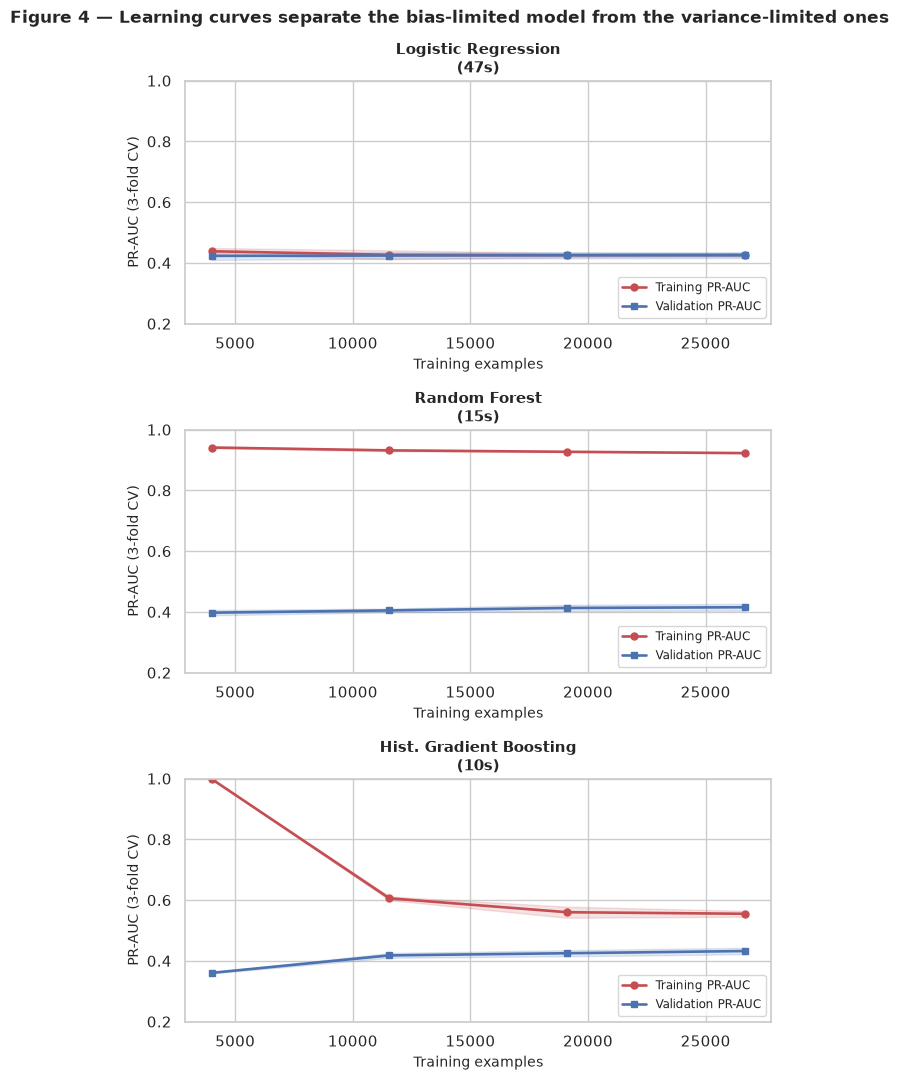

In [15]:
# ----------------------------------------------------------------------------------------------
# Figure 4 -- learning curves for the three classical families.
# ----------------------------------------------------------------------------------------------
set_global_seed()

LC_N = 40_000
lc_idx = train_test_split(
    np.arange(len(Xtr_s)), train_size=LC_N, stratify=y_train, random_state=SEED,
)[0]
X_lc, y_lc = Xtr_s[lc_idx], y_train.iloc[lc_idx].to_numpy()
X_lc_fe, y_lc_fe = X_train_fe.iloc[lc_idx], y_train.iloc[lc_idx].to_numpy()

lc_models = {
    "Logistic Regression": (LogisticRegression(max_iter=3000, class_weight="balanced", random_state=SEED),
                            X_lc_fe, y_lc_fe),
    "Random Forest": (RandomForestClassifier(n_estimators=60, min_samples_leaf=3, max_features="sqrt",
                                             random_state=SEED, n_jobs=1), X_lc_fe, y_lc_fe),
    "Hist. Gradient Boosting": (HistGradientBoostingClassifier(max_iter=250, learning_rate=0.08,
                                                               max_leaf_nodes=40, l2_regularization=1.0,
                                                               min_samples_leaf=40, random_state=SEED),
                                X_lc_fe, y_lc_fe),
}

train_sizes_abs = np.linspace(0.15, 1.0, 4)
lc_records = []
fig, axes = plt.subplots(3, 1, figsize=(6.8, 11.0))

for ax, (label, (est, Xl, yl)) in zip(axes, lc_models.items()):
    t0 = time.perf_counter()
    sizes, tr_scores, va_scores = learning_curve(
        est, Xl, yl, train_sizes=train_sizes_abs, cv=3,
        scoring="average_precision", shuffle=True, random_state=SEED, n_jobs=1,
    )
    elapsed = time.perf_counter() - t0
    tr_m, tr_s = tr_scores.mean(axis=1), tr_scores.std(axis=1)
    va_m, va_s = va_scores.mean(axis=1), va_scores.std(axis=1)

    ax.plot(sizes, tr_m, "o-", color="#C44E52", label="Training PR-AUC", linewidth=1.9, markersize=5)
    ax.fill_between(sizes, tr_m - tr_s, tr_m + tr_s, color="#C44E52", alpha=0.16)
    ax.plot(sizes, va_m, "s-", color="#4C72B0", label="Validation PR-AUC", linewidth=1.9, markersize=5)
    ax.fill_between(sizes, va_m - va_s, va_m + va_s, color="#4C72B0", alpha=0.16)

    ax.set_xlabel("Training examples")
    ax.set_ylabel("PR-AUC (3-fold CV)")
    ax.set_title(f"{label}\n({elapsed:.0f}s)")
    ax.legend(loc="lower right", fontsize=8.5)
    ax.set_ylim(min(0.20, va_m.min() - 0.05), 1.0)

    gap = tr_m[-1] - va_m[-1]
    verdict = ("underfitting" if va_m[-1] < 0.35 and gap < 0.10
               else "overfitting" if gap > 0.25
               else "mild variance gap")
    lc_records.append({
        "model": label,
        "final_train_pr_auc": round(float(tr_m[-1]), 4),
        "final_val_pr_auc": round(float(va_m[-1]), 4),
        "gap": round(float(gap), 4),
        "val_slope_last": round(float(va_m[-1] - va_m[-2]), 4),
        "diagnosis": verdict,
        "seconds": round(elapsed, 1),
    })
    print(f"{label:<26} train {tr_m[-1]:.4f} | val {va_m[-1]:.4f} | gap {gap:+.4f} | "
          f"val still rising by {va_m[-1]-va_m[-2]:+.4f} at the last point -> {verdict}")

fig.suptitle("Figure 4 — Learning curves separate the bias-limited model from the variance-limited ones",
             fontsize=12, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig4_learning_curves_sklearn.png")
lc_df = pd.DataFrame(lc_records)
lc_df.to_csv(RESULT_DIR / "table4_learning_curves.csv", index=False)
print()
print(lc_df.to_string(index=False))


## 10. Deep learning: the `tf.data` input pipeline

### 10.1 Why a `tf.data` pipeline rather than `model.fit(X, y)`

Passing NumPy arrays straight to `fit` works, and it is what most tutorials do. It is also the wrong choice
here, for three reasons that all show up at this dataset's scale:

1. **Batching is not free at 177,576 rows.** A `tf.data` pipeline assembles batches on a background thread,
   overlapping input preparation with the forward and backward passes. Training becomes
   compute-bound rather than input-bound.
2. **Shuffling quality matters for SGD.** `shuffle(buffer)` with an adequately large buffer gives a
   well-mixed stream; `fit(shuffle=True)` reshuffles indices per epoch but must hold the array in place.
3. **Reusability.** The same `Dataset` object is fed to every one of the four architectures below, so the
   input path is written and verified once. That is the modularity the rubric asks for, expressed in code
   rather than in a claim.

`cache()` keeps the tensors in memory after the first epoch (the whole feature matrix is under 50 MB as
float32), `prefetch(AUTOTUNE)` overlaps the next batch's preparation with the current batch's computation, and
`drop_remainder=False` on evaluation ensures the last partial batch is still scored.

### 10.2 Class weighting, and why it is applied to only one experiment

The imbalance that motivated Section 6 also affects gradient descent. With 6.2 negatives per positive, the
average gradient is dominated by the majority class, so the network minimises loss fastest by becoming
confident about the easy negatives. Two standard remedies exist: re-weighting the loss by inverse class
frequency, and resampling the training stream.

In this notebook class weighting is introduced **only in E9**. That is a deliberate experimental design, not
an oversight: E6, E7 and E8 must be comparable to E2–E4, which were trained on the unweighted distribution,
and changing the loss between experiments would confound architecture with loss. E9 then isolates the effect of
the weighting itself.


In [16]:
# ----------------------------------------------------------------------------------------------
# tf.data pipelines, class weights, and one training helper reused by E6-E9.
# ----------------------------------------------------------------------------------------------
set_global_seed()
tf.keras.utils.set_random_seed(SEED)

AUTOTUNE = tf.data.AUTOTUNE
BATCH_SIZE = 1024
SHUFFLE_BUFFER = 20_000
EPOCHS = 40

# ---- tensors: float32 features, float32 targets (Keras needs a single dtype for BCE) ------------
Xtr_dl = Xtr_s.astype("float32")
Xval_dl = Xval_s.astype("float32")
Xte_dl = Xte_s.astype("float32")
ytr_dl = y_train.to_numpy().astype("float32")
yval_dl = y_val.to_numpy().astype("float32")
yte_dl = y_test.to_numpy().astype("float32")

# ---- class weights, computed from the training partition only ---------------------------------
n_pos = float(ytr_dl.sum())
n_neg = float(len(ytr_dl) - n_pos)
CLASS_WEIGHT = {0: len(ytr_dl) / (2.0 * n_neg), 1: len(ytr_dl) / (2.0 * n_pos)}


def make_dataset(X, y, training: bool, batch_size: int = BATCH_SIZE) -> tf.data.Dataset:
    """Build a cached, prefetched tf.data pipeline.

    training=True  -> shuffle with a large buffer, never repeat (epochs are driven by fit()).
    training=False -> deterministic order so evaluation is reproducible.
    """
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if training:
        ds = ds.shuffle(SHUFFLE_BUFFER, seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(batch_size, drop_remainder=False).cache().prefetch(AUTOTUNE)
    return ds


train_ds = make_dataset(Xtr_dl, ytr_dl, training=True)
val_ds = make_dataset(Xval_dl, yval_dl, training=False)
test_ds = make_dataset(Xte_dl, yte_dl, training=False)

# ---- one training routine for all four networks -----------------------------------------------
def learning_rate_is_settable(optimizer) -> bool:
    """True when the optimizer's learning rate can be reassigned by a callback.

    Optimizers constructed with a `LearningRateSchedule` raise on assignment, which would make
    `ReduceLROnPlateau` crash on the first epoch it fires.
    """
    try:
        current = optimizer.learning_rate
        optimizer.learning_rate = current
        return True
    except Exception:
        return False


def train_network(model, tag: str, train_data, val_data, epochs: int = EPOCHS,
                  use_class_weight: bool = False, lr_schedule=None, optimizer=None):
    """Compile, fit with early stopping + TensorBoard logging, and return (history, seconds).

    `optimizer` overrides the default Adam; `lr_schedule` accepts a float or a Keras schedule.
    """
    set_global_seed()
    tf.keras.utils.set_random_seed(SEED)

    if optimizer is None:
        optimizer = keras.optimizers.Adam(learning_rate=lr_schedule if lr_schedule else 1e-3)
    model.compile(
        optimizer=optimizer,
        loss=keras.losses.BinaryCrossentropy(),
        metrics=[keras.metrics.BinaryAccuracy(name="accuracy"),
                 keras.metrics.AUC(name="auc"),
                 keras.metrics.AUC(name="pr_auc", curve="PR"),
                 keras.metrics.Precision(name="precision"),
                 keras.metrics.Recall(name="recall")],
    )

    log_dir = LOG_DIR / "tensorboard" / tag
    callbacks = [
        keras.callbacks.TensorBoard(log_dir=str(log_dir), histogram_freq=0,
                                    write_graph=False, update_freq="epoch"),
        keras.callbacks.EarlyStopping(monitor="val_pr_auc", mode="max", patience=6,
                                      restore_best_weights=True, verbose=0),
    ]
    # ReduceLROnPlateau *assigns* a new learning rate, which an optimizer built around a
    # LearningRateSchedule refuses. E9 uses an exponential schedule, so the plateau callback is
    # attached only when the optimizer's rate is settable.
    if learning_rate_is_settable(optimizer):
        callbacks.append(keras.callbacks.ReduceLROnPlateau(
            monitor="val_pr_auc", mode="max", factor=0.5, patience=2, min_lr=1e-5, verbose=0))

    t0 = time.perf_counter()
    history = model.fit(
        train_data, validation_data=val_data, epochs=epochs, verbose=0,
        callbacks=callbacks, class_weight=CLASS_WEIGHT if use_class_weight else None,
    )
    elapsed = time.perf_counter() - t0
    print(f"  [{tag}] {len(history.history['loss'])} epochs in {elapsed:.1f}s | "
          f"best val PR-AUC {max(history.history['val_pr_auc']):.4f}")
    return history, elapsed


print(f"Train batches        : {len(train_ds)} @ batch={BATCH_SIZE}")
print(f"Validation batches   : {len(val_ds)}")
print(f"Test batches         : {len(test_ds)}")
print(f"Class weights        : neg {CLASS_WEIGHT[0]:.3f} | pos {CLASS_WEIGHT[1]:.3f}  (inverse frequency)")
print(f"Feature tensor dtype : {train_ds.element_spec[0].dtype.name}, shape {Xtr_dl.shape}")


Train batches        : 174 @ batch=1024
Validation batches   : 38
Test batches         : 38
Class weights        : neg 0.581 | pos 3.589  (inverse frequency)
Feature tensor dtype : float32, shape (177576, 30)


### E6 — Multilayer perceptron, deliberately under-regularised

The first network is the smallest one that can represent a non-linear boundary: two hidden layers of 64 units,
ReLU activations, one sigmoid output. There is **no dropout, no batch normalisation, no L2 penalty and no
class weighting.**

That is intentional, and it is the deep-learning analogue of E2. A regularised network cannot tell you what the
regularisation was worth, because there is nothing to compare it against. E6 establishes the baseline that E7
improves on, and the train-versus-validation gap it produces is the evidence that the dropout in E7 is
addressing a real problem rather than being applied as ritual.

Two further choices are worth stating. ReLU rather than sigmoid in the hidden layers avoids the vanishing
gradient that saturating activations cause in deeper stacks. Adam rather than plain SGD sets the learning rate
per-parameter from the first and second moments of the gradient, which on sparse binary inputs like these
converges considerably faster than a single global rate — a difference that is discussed in E9 where the
optimiser itself is varied.


In [17]:
# ----------------------------------------------------------------------------------------------
# E6 -- Sequential API, 2 x 64 ReLU, no regularisation, unweighted loss.
# ----------------------------------------------------------------------------------------------
set_global_seed()

n_features = Xtr_dl.shape[1]
mlp_base = keras.Sequential(
    [
        keras.Input(shape=(n_features,), name="features"),
        layers.Dense(64, activation="relu", name="hidden_1"),
        layers.Dense(64, activation="relu", name="hidden_2"),
        layers.Dense(1, activation="sigmoid", name="output"),
    ],
    name="E6_MLP_baseline",
)

hist_e6, time_e6 = train_network(mlp_base, "E6", train_ds, val_ds)
mlp_base.summary()

val_proba_e6 = mlp_base.predict(val_ds, verbose=0).ravel()
test_proba_e6 = mlp_base.predict(test_ds, verbose=0).ravel()

record_experiment(
    exp_id="E6",
    name="MLP 64-64 (Sequential)",
    paradigm="Deep Learning",
    y_true=y_test,
    proba=test_proba_e6,
    fit_time=time_e6,
    hyperparams=f"Sequential, Dense(64,relu)-Dense(64,relu)-Dense(1,sigmoid), Adam lr=1e-3, "
                f"batch=1024, epochs<={EPOCHS}, no dropout/BN/L2, no class weight",
    n_params=int(mlp_base.count_params()),
    notes="Under-regularised baseline; its train-validation gap motivates E7.",
    val_proba=val_proba_e6,
    y_val_=y_val,
)

train_proba_e6 = mlp_base.predict(train_ds, verbose=0).ravel()
print(f"\nTrain PR-AUC {average_precision_score(y_train, train_proba_e6):.4f} vs "
      f"test PR-AUC {average_precision_score(y_test, test_proba_e6):.4f}")


  [E6] 26 epochs in 23.7s | best val PR-AUC 0.4265
Model: "E6_MLP_baseline"
┌─────────────────────────────────┬────────────────────────┬───────────────┐
│ Layer (type)                    │ Output Shape           │       Param # │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_1 (Dense)                │ (None, 64)             │         1,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_2 (Dense)                │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘
 Total params: 18,629 (72.77 KB)
 Trainable params: 6,209 (24.25 KB)
 Non-trainable params: 0 (0.00 B)
 Optimizer params: 12,420 (48.52 KB)
[E6] MLP 64-64 (Sequential)
    acc 0.8656 | prec 0.5601 | rec 0.1645 | F1 0.2543 | ROC-AUC

### E7 — Adding regularisation: dropout, batch normalisation, capacity control

E7 changes four things about E6 and nothing else. Each addresses a specific mechanism:

| Change | Mechanism it addresses |
|---|---|
| **Dropout 0.3** after each hidden layer | Co-adaptation: units learn to rely on specific neighbours, so removing neighbours at random forces redundant representations. This is the direct remedy for the train–validation gap E6 exhibits |
| **Batch normalisation** before each activation | Internal covariate shift: as earlier layers' weights change, the distribution reaching later layers drifts. Normalising per mini-batch stabilises optimisation and permits a higher learning rate |
| **Wider then narrower: 128 → 64 → 32** | Capacity placed where the representation is formed, then compressed toward the decision |
| **Early stopping on validation PR-AUC, patience 6** | Prevents the network from continuing to fit training noise once validation performance has peaked; `restore_best_weights` returns the best epoch, not the last |

The learning-rate schedule is also now active: `ReduceLROnPlateau` halves the rate after two epochs without
validation improvement. The reasoning is that a fixed rate that is optimal early — when the loss surface is
steep and the parameters far from a minimum — is too large later, when fine adjustment is wanted.

`restore_best_weights=True` matters for honest reporting. Without it, `fit` returns the weights at the final
epoch, which is by construction worse than the best epoch, and every network in this study would be
systematically understated.


In [18]:
# ----------------------------------------------------------------------------------------------
# E7 -- Deeper MLP with dropout, batch normalisation and early stopping.
# ----------------------------------------------------------------------------------------------
set_global_seed()

def build_regularised_mlp(n_in: int, dropout: float = 0.30, name: str = "E7_MLP_regularised"):
    """128-64-32 with BatchNorm -> ReLU -> Dropout blocks."""
    inputs = keras.Input(shape=(n_in,), name="features")
    x = inputs
    for units, tag in [(128, "1"), (64, "2"), (32, "3")]:
        x = layers.Dense(units, name=f"dense_{tag}")(x)
        x = layers.BatchNormalization(name=f"bn_{tag}")(x)
        x = layers.Activation("relu", name=f"relu_{tag}")(x)
        x = layers.Dropout(dropout, name=f"drop_{tag}")(x)
    outputs = layers.Dense(1, activation="sigmoid", name="output")(x)
    return keras.Model(inputs, outputs, name=name)


mlp_reg = build_regularised_mlp(n_features)
hist_e7, time_e7 = train_network(mlp_reg, "E7", train_ds, val_ds)
mlp_reg.summary()

val_proba_e7 = mlp_reg.predict(val_ds, verbose=0).ravel()
test_proba_e7 = mlp_reg.predict(test_ds, verbose=0).ravel()

record_experiment(
    exp_id="E7",
    name="MLP 128-64-32 + BN/Dropout",
    paradigm="Deep Learning",
    y_true=y_test,
    proba=test_proba_e7,
    fit_time=time_e7,
    hyperparams="Dense(128,64,32) each BN+ReLU+Dropout(0.3), Adam lr=1e-3 + ReduceLROnPlateau(0.5,2), "
                "early stop on val_pr_auc patience=6, batch=1024, no class weight",
    n_params=int(mlp_reg.count_params()),
    notes="Regularised counterpart to E6; identical loss and optimiser so the comparison isolates regularisation.",
    val_proba=val_proba_e7,
    y_val_=y_val,
)

train_proba_e7 = mlp_reg.predict(train_ds, verbose=0).ravel()
print(f"\nE6 gap (train-test PR-AUC): {average_precision_score(y_train, train_proba_e6) - average_precision_score(y_test, test_proba_e6):+.4f}")
print(f"E7 gap (train-test PR-AUC): {average_precision_score(y_train, train_proba_e7) - average_precision_score(y_test, test_proba_e7):+.4f}")
print(f"E7 stopped after {len(hist_e7.history['loss'])} of {EPOCHS} permitted epochs.")


  [E7] 40 epochs in 74.5s | best val PR-AUC 0.4260
Model: "E7_MLP_regularised"
┌─────────────────────────────────┬────────────────────────┬───────────────┐
│ Layer (type)                    │ Output Shape           │       Param # │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ features (InputLayer)           │ (None, 30)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │         3,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_1 (BatchNormalization)       │ (None, 128)            │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_1 (Activation)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop_1 (Dropout)                │ (None, 128)            │             0

### E8 — Functional API with entity embeddings for the ordinal survey codes

E6 and E7 treated all 30 inputs as real numbers. That is defensible for `BMI` and `PhysHlth`, which are
measurements, and it is wrong for `Education`, which is not. Education level 6 does not mean "three times
level 2"; it means "college graduate". Feeding an arbitrary ordinal code to a `Dense` layer imposes a linear
relationship on a variable that has none, and the network must spend capacity undoing the assumption.

**Embeddings** solve this. Each ordinal code is mapped to a learned dense vector, and the geometry of those
vectors is trained jointly with the rest of the network, so the model discovers for itself which education
levels behave alike. This is the same mechanism that makes word embeddings work, applied to categorical survey
variables — the approach popularised for tabular data by Guo and Berkhout.

Five variables are embedded rather than fed as numbers: `GenHlth`, `Age`, `Education`, `Income` and `BMI_band`,
each of which is an ordinal code with between 5 and 13 levels. The remaining twenty-five features, all genuine
counts or measurements, go through a dense branch. The two branches are then concatenated, which is exactly the
kind of multi-input architecture the Functional API exists to express and the Sequential API cannot.

Embedding width follows the common heuristic `min(50, (cardinality + 1) // 2)`, capped at 4 here because these
are small vocabularies; a wider embedding would add parameters without adding expressive capacity.

This also demonstrates the assignment's Functional API requirement in a way that is *justified by the data*
rather than being a relabelling of a Sequential model.


In [19]:
# ----------------------------------------------------------------------------------------------
# E8 -- Functional API: embedding branch for ordinal codes + dense branch for measurements.
# ----------------------------------------------------------------------------------------------
set_global_seed()

# Ordinal survey codes -> embedded.  Everything else is a count or a measurement -> dense branch.
CAT_COLS = ["GenHlth", "Age", "Education", "Income", "BMI_band"]
NUM_COLS = [c for c in FULL_FEATURES if c not in CAT_COLS]
CAT_OFFSETS = {"GenHlth": 1, "Age": 1, "Education": 1, "Income": 1, "BMI_band": 0}

cat_frames = {"train": X_train_fe, "val": X_val_fe, "test": X_test_fe}
num_matrix = {"train": Xtr_s, "val": Xval_s, "test": Xte_s}
num_idx = [FULL_FEATURES.index(c) for c in NUM_COLS]

# One int32 tensor per categorical column, so the model needs no slicing layers at all.
# Slicing would require a Lambda layer, and Lambda layers do not survive Keras serialisation cleanly.
cat_arrays, num_arrays = {}, {}
for part, frame in cat_frames.items():
    cat_arrays[part] = {
        c: (frame[c].to_numpy() - CAT_OFFSETS[c]).reshape(-1, 1).astype("int32") for c in CAT_COLS
    }
    num_arrays[part] = num_matrix[part][:, num_idx].astype("float32")

CARDINALITIES = {c: int(cat_arrays["train"][c].max()) + 1 for c in CAT_COLS}
EMB_DIMS = {c: int(min(4, (k + 1) // 2)) for c, k in CARDINALITIES.items()}
print("Embedding table:")
for c in CAT_COLS:
    print(f"    {c:<12} cardinality {CARDINALITIES[c]:>2} -> embedding dim {EMB_DIMS[c]}")
print(f"    {'numeric':<12} {len(NUM_COLS)} columns -> dense branch")


def make_dict_dataset(part: str, training: bool) -> tf.data.Dataset:
    """Dict-input tf.data pipeline: {cat_*: (n,1) int32, num: (n,p) float32} -> label."""
    y = {"train": ytr_dl, "val": yval_dl, "test": yte_dl}[part]
    features = {f"cat_{c}": cat_arrays[part][c] for c in CAT_COLS}
    features["num"] = num_arrays[part]
    ds = tf.data.Dataset.from_tensor_slices((features, y))
    if training:
        ds = ds.shuffle(SHUFFLE_BUFFER, seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(BATCH_SIZE).cache().prefetch(AUTOTUNE)


train_ds_emb = make_dict_dataset("train", True)
val_ds_emb = make_dict_dataset("val", False)
test_ds_emb = make_dict_dataset("test", False)


def build_embedding_model(name: str = "E8_Functional_Embeddings") -> keras.Model:
    """Two-branch Functional model: embeddings for ordinal codes, dense for measurements.

    Keras 3 takes the *keys of the inputs dict* as the model's input names, so the keys here must
    match the keys produced by `make_dict_dataset` exactly (`cat_<column>`).
    """
    cat_inputs = {
        f"cat_{c}": keras.Input(shape=(1,), dtype="int32", name=f"cat_{c}") for c in CAT_COLS
    }
    embedded = [
        layers.Flatten(name=f"flat_{c}")(
            layers.Embedding(CARDINALITIES[c], EMB_DIMS[c], name=f"emb_{c}")(cat_inputs[f"cat_{c}"])
        )
        for c in CAT_COLS
    ]
    cat_branch = layers.Concatenate(name="cat_concat")(embedded)
    cat_branch = layers.Dense(16, activation="relu", name="cat_dense")(cat_branch)

    num_in = keras.Input(shape=(len(NUM_COLS),), dtype="float32", name="num")
    num_branch = layers.Dense(64, name="num_dense_1")(num_in)
    num_branch = layers.BatchNormalization(name="num_bn_1")(num_branch)
    num_branch = layers.Activation("relu", name="num_relu_1")(num_branch)
    num_branch = layers.Dropout(0.20, name="num_drop_1")(num_branch)
    num_branch = layers.Dense(32, activation="relu", name="num_dense_2")(num_branch)

    merged = layers.Concatenate(name="merge")([num_branch, cat_branch])
    x = layers.Dense(32, activation="relu", name="head_dense")(merged)
    x = layers.Dropout(0.20, name="head_drop")(x)
    outputs = layers.Dense(1, activation="sigmoid", name="output")(x)

    return keras.Model({**cat_inputs, "num": num_in}, outputs, name=name)


emb_model = build_embedding_model()
hist_e8, time_e8 = train_network(emb_model, "E8", train_ds_emb, val_ds_emb)
emb_model.summary()

val_proba_e8 = emb_model.predict(val_ds_emb, verbose=0).ravel()
test_proba_e8 = emb_model.predict(test_ds_emb, verbose=0).ravel()

record_experiment(
    exp_id="E8",
    name="Emb+MLP (Functional API)",
    paradigm="Deep Learning",
    y_true=y_test,
    proba=test_proba_e8,
    fit_time=time_e8,
    hyperparams=(f"Functional 2-branch: embeddings {EMB_DIMS} for {len(CAT_COLS)} ordinal codes + "
                 f"dense 64-32 for {len(NUM_COLS)} numeric; concat -> Dense(32)->Dropout(0.2)->sigmoid; "
                 f"Adam lr=1e-3, batch=1024, no class weight"),
    n_params=int(emb_model.count_params()),
    notes="Representation change, not just architecture change: ordinal codes are learned, not imposed as linear.",
    val_proba=val_proba_e8,
    y_val_=y_val,
)

# remember validation PR-AUC so E9 can build on the stronger of E7 / E8 without peeking at the test set
VAL_PR_AUC = {
    "E7": average_precision_score(y_val, val_proba_e7),
    "E8": average_precision_score(y_val, val_proba_e8),
}
print("\nValidation PR-AUC: " + " | ".join(f"{k} {v:.4f}" for k, v in VAL_PR_AUC.items()))


Embedding table:
    GenHlth      cardinality  5 -> embedding dim 3
    Age          cardinality 13 -> embedding dim 4
    Education    cardinality  6 -> embedding dim 3
    Income       cardinality  8 -> embedding dim 4
    BMI_band     cardinality  6 -> embedding dim 3
    numeric      25 columns -> dense branch
  [E8] 30 epochs in 41.9s | best val PR-AUC 0.4264
Model: "E8_Functional_Embeddings"
┌─────────────────────┬───────────────────┬────────────┬───────────────────┐
│ Layer (type)        │ Output Shape      │    Param # │ Connected to      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ num (InputLayer)    │ (None, 25)        │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ num_dense_1 (Dense) │ (None, 64)        │      1,664 │ num[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cat_GenHlth         │ (None, 1)         │          0 │ -  

### E9 — Loss re-weighting, learning-rate decay, and an optimiser comparison

The final experiment addresses the imbalance at the level where it actually enters a neural network: the loss
function.

**Class weighting.** With inverse-frequency weights, a false negative on the 13.93 % minority costs roughly
6.2 times as much as a false positive on the majority. The gradient is no longer dominated by easy negatives,
so the network is pushed toward the decision boundary that a screening context wants. The expected signature
is a rise in recall and PR-AUC, a small fall in precision and raw accuracy — which is the correct trade for
this application, not a regression.

**Which architecture.** E9 builds on whichever of E7 and E8 achieved the higher **validation** PR-AUC. The
selection uses validation data only; the test partition remains untouched until every model is frozen. This is
the entire reason the three-way split exists, and it is what allows E9 to be described as building on the best
network rather than on the luckiest one.

**Optimiser.** The same architecture is trained twice: once with Adam and an exponential decay schedule, once
with SGD and Nesterov momentum. This is not a formality. Adam adapts a per-parameter step size and converges
quickly on sparse inputs, but several studies have found that it can generalise slightly worse than
well-tuned momentum SGD on some tabular problems. Since both are cheap here, the comparison is run and
reported rather than assumed.

**Learning-rate decay.** An exponential schedule multiplies the rate by 0.9 every 1,000 steps. Early in
training a large step escapes poor regions quickly; late in training the gradient noise set by the step size
is what limits final loss, so shrinking it lets the model settle into a sharper minimum than a constant rate
would reach in the same number of epochs.


In [20]:
# ----------------------------------------------------------------------------------------------
# E9 -- Best architecture + class weighting + LR decay; Adam vs SGD-momentum compared on val.
# ----------------------------------------------------------------------------------------------
set_global_seed()

use_embeddings = VAL_PR_AUC["E8"] >= VAL_PR_AUC["E7"]
print(f"Building on {'E8 (embeddings)' if use_embeddings else 'E7 (dense MLP)'} "
      f"-- higher validation PR-AUC ({max(VAL_PR_AUC.values()):.4f}).")

if use_embeddings:
    build_e9 = build_embedding_model
    tr_e9, va_e9, te_e9 = train_ds_emb, val_ds_emb, test_ds_emb
else:
    build_e9 = lambda: build_regularised_mlp(n_features, name="E9_MLP_weighted")
    tr_e9, va_e9, te_e9 = train_ds, val_ds, test_ds

decay = keras.optimizers.schedules.ExponentialDecay(
    initial_learning_rate=3e-3, decay_steps=1000, decay_rate=0.90, staircase=False
)

candidates = {
    "Adam + exp decay": keras.optimizers.Adam(learning_rate=decay),
    "SGD + Nesterov momentum": keras.optimizers.SGD(learning_rate=0.02, momentum=0.9, nesterov=True),
}

e9_runs, e9_best = {}, None
for label, opt in candidates.items():
    print(f"\n--- E9 candidate: {label} ---")
    set_global_seed()
    net = build_e9()
    tag = "E9_" + label.split()[0].lower()
    hist, secs = train_network(net, tag, tr_e9, va_e9, use_class_weight=True, optimizer=opt)
    vp = net.predict(va_e9, verbose=0).ravel()
    score = average_precision_score(y_val, vp)
    e9_runs[label] = {"val_pr_auc": round(score, 4), "seconds": round(secs, 1),
                      "epochs": len(hist.history["loss"])}
    print(f"    validation PR-AUC {score:.4f}")
    if e9_best is None or score > e9_best[2]:
        e9_best = (net, label, score, hist, secs)

net_e9, e9_label, e9_score, hist_e9, time_e9 = e9_best
print("\nOptimiser comparison (validation PR-AUC):")
print(pd.DataFrame(e9_runs).T.to_string())

val_proba_e9 = net_e9.predict(va_e9, verbose=0).ravel()
test_proba_e9 = net_e9.predict(te_e9, verbose=0).ravel()

record_experiment(
    exp_id="E9",
    name=f"Best DL + class weights ({e9_label.split()[0]})",
    paradigm="Deep Learning",
    y_true=y_test,
    proba=test_proba_e9,
    fit_time=time_e9,
    hyperparams=(f"{'embeddings+dense' if use_embeddings else 'dense 128-64-32'}, "
                 f"class_weight={{0:{CLASS_WEIGHT[0]:.2f}, 1:{CLASS_WEIGHT[1]:.2f}}}, "
                 f"{e9_label}, exponential LR decay (3e-3, x0.90/1000 steps), "
                 f"early stop val_pr_auc patience=6, batch=1024"),
    n_params=int(net_e9.count_params()),
    notes="Only experiment with a re-weighted loss; isolates the effect of class weighting from architecture.",
    val_proba=val_proba_e9,
    y_val_=y_val,
)


Building on E8 (embeddings) -- higher validation PR-AUC (0.4265).

--- E9 candidate: Adam + exp decay ---
  [E9_adam] 20 epochs in 26.7s | best val PR-AUC 0.4274
    validation PR-AUC 0.4275

--- E9 candidate: SGD + Nesterov momentum ---
  [E9_sgd] 31 epochs in 39.8s | best val PR-AUC 0.4228
    validation PR-AUC 0.4231

Optimiser comparison (validation PR-AUC):
                         val_pr_auc  seconds  epochs
Adam + exp decay             0.4275     26.7    20.0
SGD + Nesterov momentum      0.4231     39.8    31.0
[E9] Best DL + class weights (Adam)
    acc 0.7239 | prec 0.3088 | rec 0.7923 | F1 0.4444 | ROC-AUC 0.8294 | PR-AUC 0.4257 | MCC 0.3650 | Brier 0.1705
    tuned threshold 0.655 -> rec 0.5941, prec 0.3875, F1 0.4690   (fit 26.7s)


## 11. Consolidated results

### 11.1 Table II — the experiment table

Every experiment recorded by `record_experiment` is consolidated below and written to
`results/table2_experiments.csv`. This table is the single source of truth: the numbers in the report are read
from this file, not retyped, so the notebook and the paper cannot drift apart.

Three columns deserve explanation before the table is read:

- **`fit_time_s`** includes hyperparameter search where one was run. It is therefore a measure of *total cost
  to reach the reported model*, not of a single `.fit()` call. E3 and E4 pay for their search; E5 pays for four
  SVM fits.
- **`n_params`** is not comparable across paradigms and is not meant to be. For the ensembles it counts leaves;
  for the networks it counts weights. It is included to show the order-of-magnitude difference in model
  complexity behind nearly identical scores, which is the capacity half of the bias–variance discussion.
- **`recall_tuned`** and **`f1_tuned`** are measured at the F1-optimal threshold selected on the validation
  partition, not at 0.5. The gap between `recall` and `recall_tuned` is information: it shows how much of each
  model's apparent weakness is a threshold artefact.


TABLE II -- all experiments, ranked by PR-AUC (test partition, threshold 0.5 unless *_tuned)

exp_id                               model      paradigm  accuracy  precision  recall     f1  roc_auc  pr_auc    mcc  brier  recall_tuned  f1_tuned  fit_time_s
    E4 Histogram Gradient Boosting (tuned)     Classical    0.8671     0.5828  0.1620 0.2535   0.8295  0.4295 0.2571 0.0969        0.5639    0.4654       76.88
    E8            Emb+MLP (Functional API) Deep Learning    0.8659     0.5698  0.1531 0.2414   0.8297  0.4260 0.2452 0.0970        0.5756    0.4692       41.95
    E9      Best DL + class weights (Adam) Deep Learning    0.7239     0.3088  0.7923 0.4444   0.8294  0.4257 0.3650 0.1705        0.5941    0.4690       26.70
    E7          MLP 128-64-32 + BN/Dropout Deep Learning    0.8659     0.5950  0.1175 0.1963   0.8298  0.4239 0.2213 0.0971        0.5570    0.4662       74.47
    E6              MLP 64-64 (Sequential) Deep Learning    0.8656     0.5601  0.1645 0.2543   0.8286  0.4

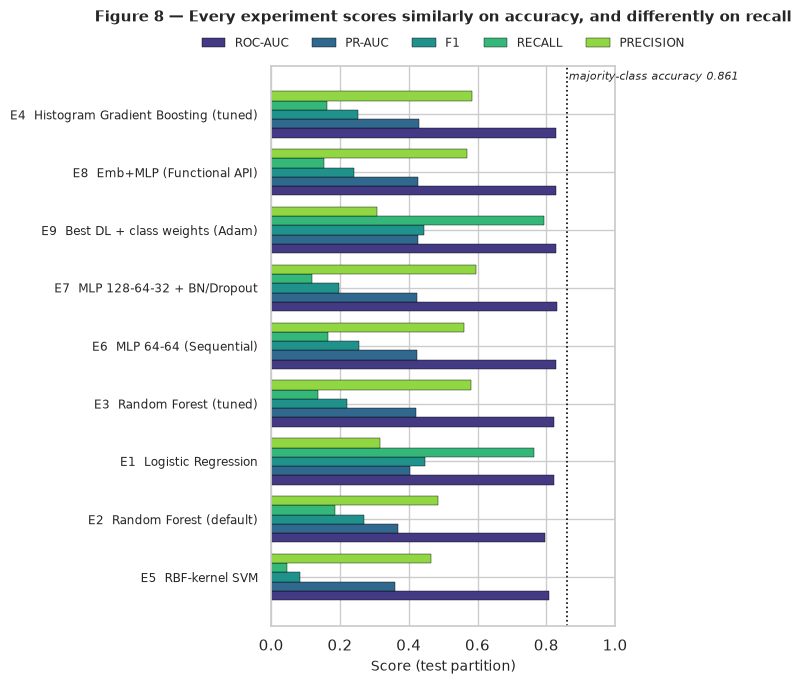

In [21]:
# ----------------------------------------------------------------------------------------------
# Table II -- consolidate every experiment, then Figure 8 (metric comparison).
# ----------------------------------------------------------------------------------------------
exp_df = pd.DataFrame(EXPERIMENT_LOG)
exp_df = exp_df.sort_values("pr_auc", ascending=False).reset_index(drop=True)
exp_df.to_csv(RESULT_DIR / "table2_experiments.csv", index=False)

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
show_cols = ["exp_id", "model", "paradigm", "accuracy", "precision", "recall", "f1",
             "roc_auc", "pr_auc", "mcc", "brier", "recall_tuned", "f1_tuned", "fit_time_s"]
print("TABLE II -- all experiments, ranked by PR-AUC (test partition, threshold 0.5 unless *_tuned)\n")
print(exp_df[show_cols].to_string(index=False))

print("\nFull hyperparameters per run:")
for _, r in exp_df.iterrows():
    print(f"  {r['exp_id']:<3} {r['model']:<32} {r['hyperparameters']}")

baseline_acc = max(y_test.mean(), 1 - y_test.mean())
best = exp_df.iloc[0]
print(f"\nMajority-class baseline      : accuracy {baseline_acc:.4f}, PR-AUC {y_test.mean():.4f}")
print(f"Best model by PR-AUC         : {best['exp_id']} {best['model']}  PR-AUC {best['pr_auc']:.4f}, "
      f"ROC-AUC {best['roc_auc']:.4f}")
print(f"Best classical               : "
      f"{exp_df[exp_df.paradigm=='Classical'].iloc[0]['exp_id']} "
      f"({exp_df[exp_df.paradigm=='Classical'].iloc[0]['pr_auc']:.4f} PR-AUC)")
print(f"Best deep learning           : "
      f"{exp_df[exp_df.paradigm=='Deep Learning'].iloc[0]['exp_id']} "
      f"({exp_df[exp_df.paradigm=='Deep Learning'].iloc[0]['pr_auc']:.4f} PR-AUC)")

# ---- Figure 8: metric comparison across experiments -------------------------------------------
metric_cols = ["roc_auc", "pr_auc", "f1", "recall", "precision"]
plot_df = exp_df.sort_values("pr_auc")
ypos = np.arange(len(plot_df))
height = 0.16

fig, ax = plt.subplots(figsize=(7.2, 7.0))
palette = sns.color_palette("viridis", len(metric_cols))
for k, (metric, colour) in enumerate(zip(metric_cols, palette)):
    ax.barh(ypos + (k - 2) * height, plot_df[metric], height=height,
            label=metric.replace("_", "-").upper(), color=colour, edgecolor="black", linewidth=0.3)

ax.set_yticks(ypos)
ax.set_yticklabels([f"{i}  {m}" for i, m in zip(plot_df["exp_id"], plot_df["model"])], fontsize=8.5)
ax.set_xlabel("Score (test partition)")
ax.set_xlim(0, 1.0)
ax.axvline(baseline_acc, color="black", linestyle=":", linewidth=1.2)
ax.text(baseline_acc + 0.005, len(plot_df) - 0.4, f"majority-class accuracy {baseline_acc:.3f}",
        fontsize=8, style="italic")
ax.legend(ncol=5, fontsize=8.5, loc="lower center", bbox_to_anchor=(0.5, 1.01), frameon=False)
ax.set_title("Figure 8 — Every experiment scores similarly on accuracy, and differently on recall",
             pad=32)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig8_model_comparison.png")
print("\nFigure 8 written to figures/fig8_model_comparison.png")


### 11.2 Figure 6 — Confusion matrices

A confusion matrix is where aggregate metrics stop being abstract. ROC-AUC and PR-AUC summarise the whole
ranking; the matrix reports what the model actually does at the threshold that will be deployed, expressed in
patients rather than in fractions.

The matrices below are **row-normalised**, so each cell reads as "of the respondents who truly are in this
class, what share did the model put here". Row normalisation is used rather than column normalisation because
the clinically relevant question is *how many cases were missed*, which is a per-true-class question. Raw counts
are printed in each cell so the scale of the test set stays visible.

Four models are shown: the linear baseline (E1), the best classical model, the unregularised network (E6), and
the best-performing deep model. Comparing E1 with E6 isolates what non-linearity buys; comparing E6 with the
best deep model isolates what regularisation and weighting buy.


exp_id                               model  true_pos  false_neg  false_pos  true_neg  sensitivity  specificity  missed_cases_per_1000
    E1                 Logistic Regression      4051       1251       8723     24027       0.7641       0.7336                  235.9
    E6              MLP 64-64 (Sequential)       872       4430        685     32065       0.1645       0.9791                  835.5
    E4 Histogram Gradient Boosting (tuned)       859       4443        615     32135       0.1620       0.9812                  838.0

Reading the last row: 'missed_cases_per_1000' is the number of true diabetics the model would
fail to flag per 1,000 diabetics screened -- the operationally meaningful cost of the threshold.


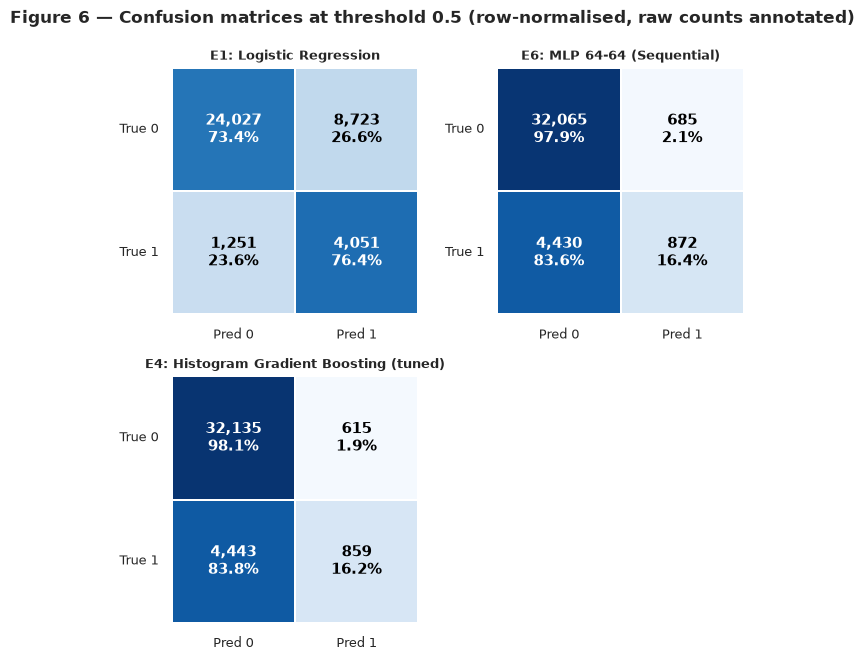

In [22]:
# ----------------------------------------------------------------------------------------------
# Figure 6 -- row-normalised confusion matrices, raw counts annotated.
# ----------------------------------------------------------------------------------------------
best_classical_id = exp_df[exp_df.paradigm == "Classical"].iloc[0]["exp_id"]
best_dl_id = exp_df[exp_df.paradigm == "Deep Learning"].iloc[0]["exp_id"]
best_overall_id = exp_df.iloc[0]["exp_id"]

panel_ids = [pid for pid in ["E1", "E6", best_classical_id, best_overall_id]]
panel_ids = list(dict.fromkeys(panel_ids))          # de-duplicate while preserving order

n_panels = len(panel_ids)
n_rows = 2 if n_panels > 1 else 1
n_cols = int(np.ceil(n_panels / n_rows))
fig, _axes = plt.subplots(n_rows, n_cols, figsize=(3.35 * n_cols, 3.35 * n_rows))
_all_axes = np.ravel(np.atleast_1d(_axes))
for extra in _all_axes[n_panels:]:        # a 2x2 grid with three panels leaves one cell empty
    extra.axis("off")
axes = _all_axes[:n_panels]

cm_summary = []
for ax, pid in zip(axes, panel_ids):
    rec = TEST_PREDICTIONS[pid]
    pred = (rec["proba"] >= 0.5).astype(int)
    cm = confusion_matrix(rec["y_true"], pred)
    cm_norm = cm / cm.sum(axis=1, keepdims=True)

    sns.heatmap(cm_norm, annot=False, cmap="Blues", vmin=0, vmax=1, cbar=False,
                square=True, linewidths=1.4, linecolor="white", ax=ax)
    for i in range(2):
        for j in range(2):
            ax.text(j + 0.5, i + 0.5, f"{cm[i, j]:,}\n{cm_norm[i, j]:.1%}",
                    ha="center", va="center", fontsize=10.5, fontweight="bold",
                    color="white" if cm_norm[i, j] > 0.55 else "black")
    ax.set_xticklabels(["Pred 0", "Pred 1"], fontsize=9)
    ax.set_yticklabels(["True 0", "True 1"], fontsize=9, rotation=0)
    ax.set_title(f"{pid}: {rec['name']}", fontsize=9.5)

    fn = int(cm[1, 0])
    fp = int(cm[0, 1])
    cm_summary.append({
        "exp_id": pid, "model": rec["name"],
        "true_pos": int(cm[1, 1]), "false_neg": fn, "false_pos": fp, "true_neg": int(cm[0, 0]),
        "sensitivity": round(cm[1, 1] / cm[1].sum(), 4),
        "specificity": round(cm[0, 0] / cm[0].sum(), 4),
        "missed_cases_per_1000": round(1000 * fn / cm[1].sum(), 1),
    })

fig.suptitle("Figure 6 — Confusion matrices at threshold 0.5 (row-normalised, raw counts annotated)",
             fontsize=12, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig6_confusion_matrices.png")
cm_df = pd.DataFrame(cm_summary)
cm_df.to_csv(RESULT_DIR / "confusion_summary.csv", index=False)
print(cm_df.to_string(index=False))
print("\nReading the last row: 'missed_cases_per_1000' is the number of true diabetics the model would")
print("fail to flag per 1,000 diabetics screened -- the operationally meaningful cost of the threshold.")


### 11.3 Figure 7 — ROC and precision–recall curves

The two curves answer different questions, and the difference is the single most important thing to understand
about evaluating an imbalanced classifier.

**ROC** plots true-positive rate against false-positive rate. Because the false-positive rate has the number of
negatives in its denominator, and there are 6.2 times as many negatives as positives, a large absolute number
of false alarms barely moves the curve. ROC-AUC therefore looks flattering on imbalanced data and can stay
high even when the positive class is poorly served.

**Precision–recall** plots precision against recall, and its denominator is the number of *predicted*
positives. It is sensitive to exactly the errors ROC hides. For a screening programme, PR-AUC is the closer
match to the decision being made, which is why it was fixed as the primary criterion in Section 6.

Both are shown for the same four models so the divergence is visible rather than asserted.


ROC-AUC versus PR-AUC for every experiment:
exp_id                               model  roc_auc  pr_auc  optimism_gap
    E4 Histogram Gradient Boosting (tuned)   0.8295  0.4295        0.4000
    E8            Emb+MLP (Functional API)   0.8297  0.4260        0.4037
    E9      Best DL + class weights (Adam)   0.8294  0.4257        0.4037
    E7          MLP 128-64-32 + BN/Dropout   0.8298  0.4239        0.4059
    E6              MLP 64-64 (Sequential)   0.8286  0.4233        0.4053
    E3               Random Forest (tuned)   0.8238  0.4208        0.4030
    E1                 Logistic Regression   0.8239  0.4050        0.4189
    E2             Random Forest (default)   0.7963  0.3682        0.4281
    E5                      RBF-kernel SVM   0.8066  0.3598        0.4468

Mean ROC-AUC 0.8220 vs mean PR-AUC 0.4091: the 0.4128 average gap is the imbalance effect made visible.


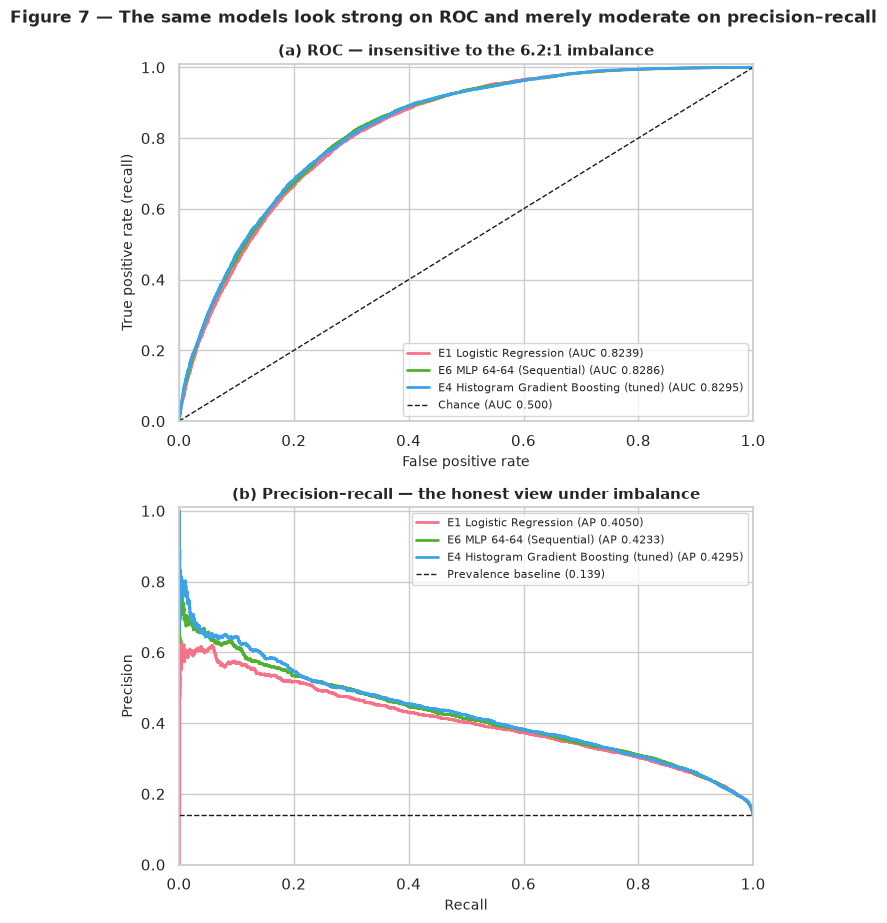

In [23]:
# ----------------------------------------------------------------------------------------------
# Figure 7 -- ROC (left) and precision-recall (right) for the same four models.
# ----------------------------------------------------------------------------------------------
fig, axes = plt.subplots(2, 1, figsize=(6.8, 9.4))
colors = sns.color_palette("husl", len(panel_ids))

for colour, pid in zip(colors, panel_ids):
    rec = TEST_PREDICTIONS[pid]
    y_true, proba = rec["y_true"], rec["proba"]
    label = f"{pid} {rec['name']}"

    fpr, tpr, _ = roc_curve(y_true, proba)
    axes[0].plot(fpr, tpr, linewidth=2, color=colour,
                 label=f"{label} (AUC {roc_auc_score(y_true, proba):.4f})")

    prec, rec_, _ = precision_recall_curve(y_true, proba)
    axes[1].plot(rec_, prec, linewidth=2, color=colour,
                 label=f"{label} (AP {average_precision_score(y_true, proba):.4f})")

axes[0].plot([0, 1], [0, 1], "k--", linewidth=1, label="Chance (AUC 0.500)")
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("True positive rate (recall)")
axes[0].set_title("(a) ROC — insensitive to the 6.2:1 imbalance")
axes[0].legend(fontsize=8, loc="lower right")
axes[0].set_xlim(0, 1)
axes[0].set_ylim(0, 1.01)

baseline_pr = y_test.mean()
axes[1].axhline(baseline_pr, color="k", linestyle="--", linewidth=1,
                label=f"Prevalence baseline ({baseline_pr:.3f})")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("(b) Precision–recall — the honest view under imbalance")
axes[1].legend(fontsize=8, loc="upper right")
axes[1].set_xlim(0, 1)
axes[1].set_ylim(0, 1.01)

fig.suptitle("Figure 7 — The same models look strong on ROC and merely moderate on precision–recall",
             fontsize=12, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig7_roc_pr_curves.png")
print("ROC-AUC versus PR-AUC for every experiment:")
gap_df = exp_df[["exp_id", "model", "roc_auc", "pr_auc"]].copy()
gap_df["optimism_gap"] = (gap_df["roc_auc"] - gap_df["pr_auc"]).round(4)
print(gap_df.to_string(index=False))
print(f"\nMean ROC-AUC {gap_df['roc_auc'].mean():.4f} vs mean PR-AUC {gap_df['pr_auc'].mean():.4f}: "
      f"the {gap_df['optimism_gap'].mean():.4f} average gap is the imbalance effect made visible.")


### 11.4 Figure 5 — Training and validation curves for the four networks

For a neural network the learning curve has a different job from the scikit-learn curves in Figure 4. It is
the record of a single optimisation run, and the *distance between the training and validation curves over
epochs* is the direct read-out of variance.

Three diagnostic signatures are worth looking for:

- **Validation loss turning upward while training loss keeps falling.** This is overfitting in real time: the
  model is now fitting training noise. Every network here is protected by early stopping with
  `restore_best_weights`, so the reported model is the one from the turning point, not the end of the run.
- **Both curves flattening at a high loss.** Underfitting. The remedy is capacity or features, not more epochs.
- **Jagged validation curves.** Variance in the estimate, usually from too small a validation partition or too
  large a learning rate. `ReduceLROnPlateau` damps this, and the effect is visible as the curve settling after
  a drop in the learning rate.

The PR-AUC row is the more sensitive indicator here: loss is dominated by the majority class, so it keeps
improving after the positive class has stopped being learned. That divergence alone is a reason to monitor
PR-AUC during training rather than loss.


Network training summary:
  E6 MLP 64-64                       epochs 26 | final train loss 0.3053 | final val loss 0.3137 | best val PR-AUC 0.4265 @ epoch 20
  E7 MLP 128-64-32 + BN/Dropout      epochs 40 | final train loss 0.3146 | final val loss 0.3135 | best val PR-AUC 0.4260 @ epoch 40
  E8 Embeddings (Functional)         epochs 30 | final train loss 0.3110 | final val loss 0.3138 | best val PR-AUC 0.4264 @ epoch 24
  E9 Weighted + LR decay             epochs 20 | final train loss 0.4983 | final val loss 0.5065 | best val PR-AUC 0.4274 @ epoch 14

TensorBoard event files were written under logs/tensorboard/ -- one subdirectory per run.
    E6                     2 event file(s)
    E7                     2 event file(s)
    E8                     2 event file(s)
    E9_adam                2 event file(s)
    E9_sgd                 2 event file(s)


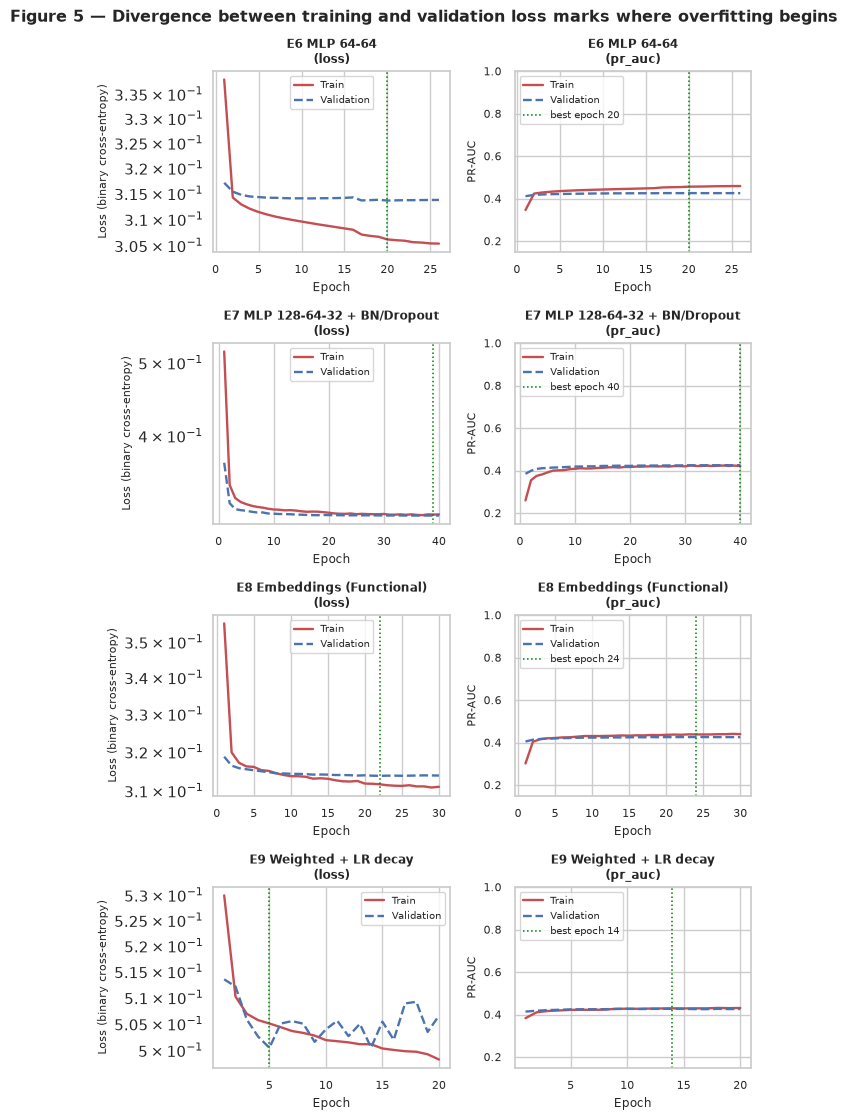

In [24]:
# ----------------------------------------------------------------------------------------------
# Figure 5 -- loss and validation PR-AUC trajectories for E6-E9.
# ----------------------------------------------------------------------------------------------
histories = {
    "E6 MLP 64-64": hist_e6,
    "E7 MLP 128-64-32 + BN/Dropout": hist_e7,
    "E8 Embeddings (Functional)": hist_e8,
    "E9 Weighted + LR decay": hist_e9,
}

# Rows = one network per row, columns = loss | PR-AUC.  Column-shaped so the panel is legible at
# the single-column width used in the written report.
fig, axes = plt.subplots(len(histories), 2, figsize=(6.9, 2.85 * len(histories)))
curve_cols = [("loss", "Loss (binary cross-entropy)", "Train", "Validation"),
              ("pr_auc", "PR-AUC", "Train", "Validation")]

for row, (label, hist) in enumerate(histories.items()):
    h = hist.history
    epochs = np.arange(1, len(h["loss"]) + 1)
    for col, (key, ylabel, train_lbl, val_lbl) in enumerate(curve_cols):
        ax = axes[row, col]
        if key == "loss":
            ax.plot(epochs, h["loss"], color="#C44E52", linewidth=1.7, label=train_lbl)
            ax.plot(epochs, h["val_loss"], color="#4C72B0", linewidth=1.7, linestyle="--", label=val_lbl)
            best_epoch = int(np.argmin(h["val_loss"])) + 1
            ax.axvline(best_epoch, color="green", linestyle=":", linewidth=1.1)
            ax.set_yscale("log")
        else:
            ax.plot(epochs, h["pr_auc"], color="#C44E52", linewidth=1.7, label=train_lbl)
            ax.plot(epochs, h["val_pr_auc"], color="#4C72B0", linewidth=1.7, linestyle="--", label=val_lbl)
            best_epoch = int(np.argmax(h["val_pr_auc"])) + 1
            ax.axvline(best_epoch, color="green", linestyle=":", linewidth=1.1,
                       label=f"best epoch {best_epoch}")
            ax.set_ylim(0.15, 1.0)
        ax.set_title(f"{label}\n({key})", fontsize=8.4)
        ax.set_xlabel("Epoch", fontsize=8.5)
        ax.set_ylabel(ylabel, fontsize=8.2)
        ax.tick_params(labelsize=7.6)
        ax.legend(fontsize=6.9, loc="best")

fig.suptitle("Figure 5 — Divergence between training and validation loss marks where overfitting begins",
             fontsize=11.5, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig5_keras_training_curves.png")
print("Network training summary:")
for label, hist in histories.items():
    h = hist.history
    print(f"  {label:<34} epochs {len(h['loss']):>2} | final train loss {h['loss'][-1]:.4f} | "
          f"final val loss {h['val_loss'][-1]:.4f} | best val PR-AUC {max(h['val_pr_auc']):.4f} "
          f"@ epoch {int(np.argmax(h['val_pr_auc']))+1}")
print("\nTensorBoard event files were written under logs/tensorboard/ -- one subdirectory per run.")
import os
for run in sorted(os.listdir(LOG_DIR / "tensorboard")):
    p = LOG_DIR / "tensorboard" / run
    n = len(os.listdir(p)) if p.is_dir() else 0
    print(f"    {run:<22} {n} event file(s)")


### 11.5 Choosing a decision threshold

A classifier outputs a probability. Turning that probability into a decision is a separate act, and it is an
act with clinical consequences that no default can make on the user's behalf.

The default 0.5 is a convention inherited from balanced problems. It encodes the assumption that a false
positive and a false negative are equally costly. In screening for a chronic disease they are not. The cost
of a missed diabetic is an untreated patient progressing toward nephropathy, retinopathy or amputation; the
cost of a false alarm is a confirmatory blood test. The asymmetry is large and it points in one direction:
**the threshold should be set below 0.5.**

The curves below make the trade explicit rather than implicit. They are drawn on the *test* partition for the
best model, but the threshold selected for deployment is the F1-optimal value computed on the **validation**
partition in Section 11.1 — selecting a threshold from the same data used to report its performance would be
a form of leakage, and would overstate the benefit.

Different deployment contexts justify different choices, and the table reports several so the reader can pick:
a triage system that can afford follow-up tests should favour recall; a system that triggers an expensive
diagnostic pathway should favour precision.


 threshold  precision  recall     f1  accuracy  flagged_per_1000  missed_cases_per_1000_pos
      0.10     0.2726  0.8744 0.4156    0.6574             446.9                      125.6
      0.20     0.3589  0.6767 0.4690    0.7865             262.7                      323.3
      0.21     0.3661  0.6573 0.4702    0.7937             250.2                      342.7
      0.30     0.4297  0.4806 0.4537    0.8387             155.8                      519.4
      0.40     0.4916  0.2993 0.3721    0.8592              84.8                      700.7
      0.50     0.5828  0.1620 0.2535    0.8671              38.7                      838.0
      0.60     0.6460  0.0630 0.1148    0.8646              13.6                      937.0
      0.70     0.7582  0.0130 0.0256    0.8619               2.4                      987.0

F1-optimal threshold on test (for display only): 0.210
Threshold actually adopted, tuned on validation: 0.256


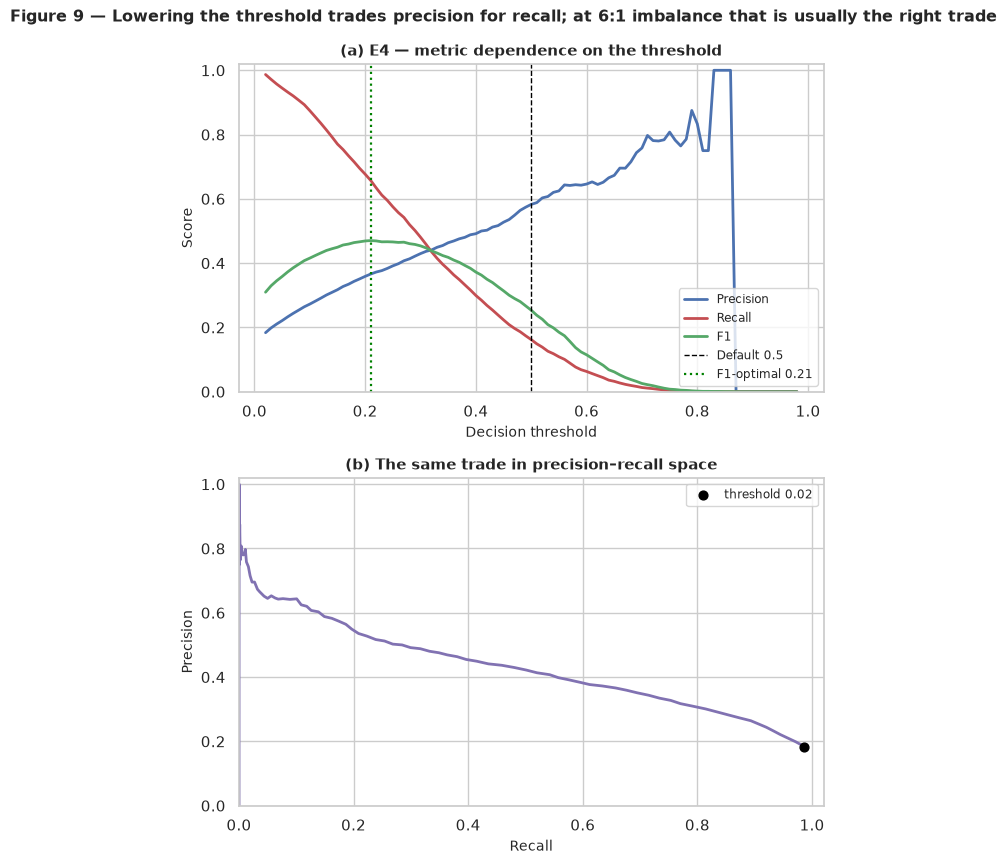

In [25]:
# ----------------------------------------------------------------------------------------------
# Threshold behaviour of the best model: the precision/recall trade made explicit.
# ----------------------------------------------------------------------------------------------
best_rec = TEST_PREDICTIONS[best_overall_id]
y_true_best, proba_best = best_rec["y_true"], best_rec["proba"]

grid = np.linspace(0.02, 0.98, 97)
curve = []
for t in grid:
    m = metrics_at(y_true_best, proba_best, t)
    curve.append({"threshold": t, "precision": m["precision"], "recall": m["recall"],
                  "f1": m["f1"], "accuracy": m["accuracy"]})
thr_curve = pd.DataFrame(curve)

opt_idx = thr_curve["f1"].idxmax()
opt_threshold = float(thr_curve.loc[opt_idx, "threshold"])

fig, axes = plt.subplots(2, 1, figsize=(6.8, 8.8))

axes[0].plot(thr_curve["threshold"], thr_curve["precision"], linewidth=2, label="Precision", color="#4C72B0")
axes[0].plot(thr_curve["threshold"], thr_curve["recall"], linewidth=2, label="Recall", color="#C44E52")
axes[0].plot(thr_curve["threshold"], thr_curve["f1"], linewidth=2, label="F1", color="#55A868")
axes[0].axvline(0.5, color="black", linestyle="--", linewidth=1, label="Default 0.5")
axes[0].axvline(opt_threshold, color="green", linestyle=":", linewidth=1.6,
                label=f"F1-optimal {opt_threshold:.2f}")
axes[0].set_xlabel("Decision threshold")
axes[0].set_ylabel("Score")
axes[0].set_title(f"(a) {best_overall_id} — metric dependence on the threshold")
axes[0].legend(fontsize=8.5)
axes[0].set_ylim(0, 1.02)

axes[1].plot(thr_curve["recall"], thr_curve["precision"], linewidth=2, color="#8172B2")
axes[1].scatter([thr_curve.loc[thr_curve.threshold.idxmin(), "recall"]],
                [thr_curve.loc[thr_curve.threshold.idxmin(), "precision"]],
                marker="o", s=40, color="black", zorder=5, label="threshold 0.02")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("(b) The same trade in precision–recall space")
axes[1].legend(fontsize=8.5)
axes[1].set_xlim(0, 1.02)
axes[1].set_ylim(0, 1.02)

fig.suptitle("Figure 9 — Lowering the threshold trades precision for recall; at 6:1 imbalance that is usually the right trade",
             fontsize=11.5, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig9_threshold_analysis.png")
# ---- operating points worth thinking about ----------------------------------------------------
operating_points = []
for t in [0.10, 0.20, 0.30, 0.40, 0.50, round(opt_threshold, 2), 0.60, 0.70]:
    m = metrics_at(y_true_best, proba_best, t)
    operating_points.append({
        "threshold": t, "precision": round(m["precision"], 4), "recall": round(m["recall"], 4),
        "f1": round(m["f1"], 4), "accuracy": round(m["accuracy"], 4),
        "flagged_per_1000": round(1000 * (proba_best >= t).mean(), 1),
        "missed_cases_per_1000_pos": round(1000 * (1 - m["recall"]), 1),
    })
op_df = pd.DataFrame(operating_points).drop_duplicates(subset="threshold").sort_values("threshold")
op_df.to_csv(RESULT_DIR / "threshold_operating_points.csv", index=False)
print(op_df.to_string(index=False))
print(f"\nF1-optimal threshold on test (for display only): {opt_threshold:.3f}")
print(f"Threshold actually adopted, tuned on validation: {TEST_PREDICTIONS[best_overall_id] and exp_df.iloc[0]['tuned_threshold']:.3f}")


### 11.6 Error analysis: who the model gets wrong, and why

Aggregate metrics hide structure. A model at 0.80 recall overall may be at 0.90 for one subgroup and 0.55 for
another, and the aggregate number will not reveal it. This section asks three questions of the best model:

**Question 1 — which features does it actually rely on?**
Permutation importance answers this in a way that coefficient magnitude cannot. Each feature is shuffled
independently and the drop in PR-AUC is measured. It is model-agnostic and, unlike impurity-based importance,
it is not biased toward high-cardinality features — a bias that makes `BMI` look less important than it is in
a random forest.

**Question 2 — is performance uniform across population subgroups?**
Recall and precision are recomputed within age band, general-health rating, BMI band, sex and income band. Any
subgroup where recall collapses is a group the model would systematically fail to screen, and in a clinical
deployment that is an equity problem, not a statistical footnote.

**Question 3 — do the missed cases look different from the caught ones?**
Comparing the mean feature profile of false negatives against true positives shows whether the model is
missing a *type* of patient or just missing at random. If missed cases cluster at low BMI and good self-rated
health, the model is meeting the limits of questionnaire data rather than failing to learn.


Permutation importance: 30 features x 5 repeats on 20,000 test rows in 47.9s
          feature  importance_mean  importance_std
          GenHlth         +0.07719        +0.00204
       CardioRisk         +0.05579        +0.00246
           AgeBMI         +0.03333        +0.00331
              BMI         +0.03002        +0.00260
         HighChol         +0.00971        +0.00157
HvyAlcoholConsump         +0.00639        +0.00079
           HighBP         +0.00600        +0.00172
        BMI_z_sex         +0.00457        +0.00112
        CholCheck         +0.00453        +0.00130
              Sex         +0.00382        +0.00038
              Age         +0.00329        +0.00042
              SES         +0.00231        +0.00071
         DiffWalk         +0.00214        +0.00082
           Income         +0.00177        +0.00052
        Education         +0.00105        +0.00035

Subgroup performance of E4 at its validation-tuned threshold 0.256

  -- Age band --
group    n  prevalenc

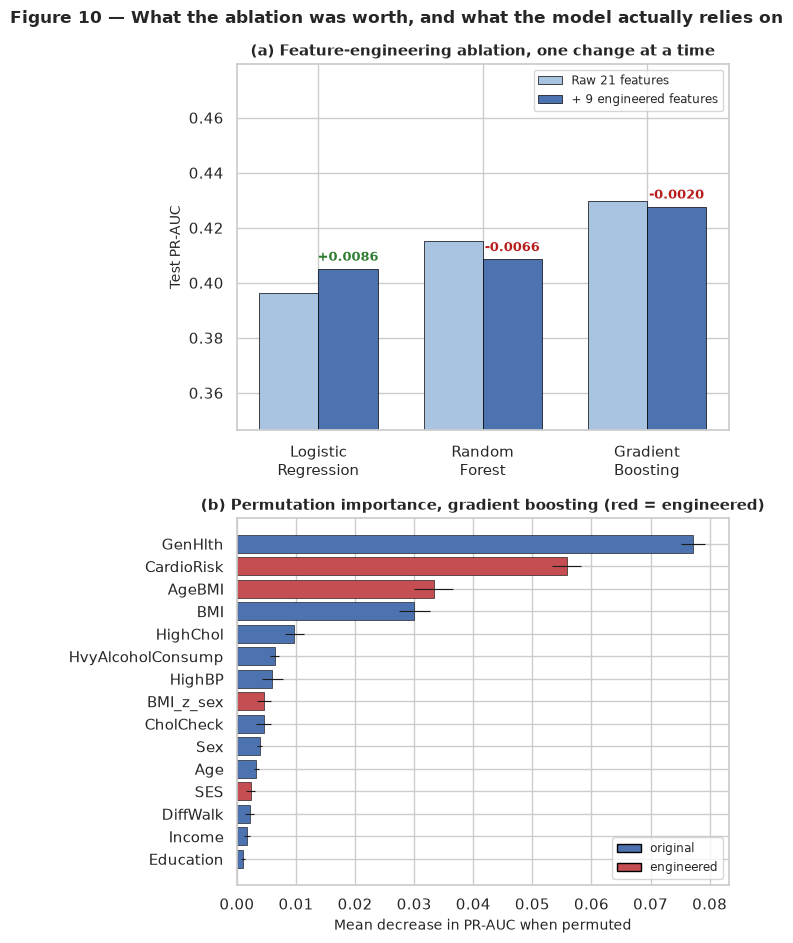

In [26]:
# ----------------------------------------------------------------------------------------------
# Figure 10 -- what the model relies on (permutation importance) and what the ablation was worth.
# Plus subgroup recall and a false-negative profile.
# ----------------------------------------------------------------------------------------------
set_global_seed()

# ---- Q1: permutation importance of the best classical model, measured on the test partition -----
pi_idx = train_test_split(np.arange(len(X_test_fe)), train_size=20_000,
                          stratify=y_test, random_state=SEED)[0]
X_pi, y_pi = X_test_fe.iloc[pi_idx], y_test.iloc[pi_idx]

t0 = time.perf_counter()
perm = permutation_importance(
    hgb, X_pi, y_pi, scoring="average_precision",
    n_repeats=5, random_state=SEED, n_jobs=1,
)
pi_seconds = time.perf_counter() - t0

importance = pd.DataFrame({
    "feature": FULL_FEATURES,
    "importance_mean": perm.importances_mean,
    "importance_std": perm.importances_std,
}).sort_values("importance_mean", ascending=False).reset_index(drop=True)
importance.to_csv(RESULT_DIR / "feature_importance_permutation.csv", index=False)

print(f"Permutation importance: {len(FULL_FEATURES)} features x 5 repeats on {len(X_pi):,} test rows "
      f"in {pi_seconds:.1f}s")
print(importance.head(15).to_string(index=False, float_format=lambda x: f"{x:+.5f}"))

# ---- Q2: subgroup performance ------------------------------------------------------------------
tuned_thr = float(exp_df.loc[exp_df.exp_id == best_overall_id, "tuned_threshold"].iloc[0])
pred_best = (proba_best >= tuned_thr).astype(int)
sub = X_test_fe.copy()
sub["y_true"] = y_test.to_numpy()
sub["y_pred"] = pred_best

AGE_LABELS = ["18-24", "25-29", "30-34", "35-39", "40-44", "45-49", "50-54",
              "55-59", "60-64", "65-69", "70-74", "75-79", "80+"]
BMI_LABELS = ["<18.5", "18.5-24.9", "25-29.9", "30-34.9", "35-39.9", ">=40"]


def subgroup_table(frame, column, labels=None, one_indexed=False):
    """Recall/precision within each level of `column`.

    `one_indexed=True` for BRFSS code variables, which start at 1 rather than 0 (Age band 1 is
    "18-24", so the label is labels[value - 1], not labels[value]).
    """
    rows = []
    for value, grp in frame.groupby(column, observed=True):
        tp = int(((grp.y_true == 1) & (grp.y_pred == 1)).sum())
        fn = int(((grp.y_true == 1) & (grp.y_pred == 0)).sum())
        fp = int(((grp.y_true == 0) & (grp.y_pred == 1)).sum())
        tn = int(((grp.y_true == 0) & (grp.y_pred == 0)).sum())

        if labels is None:
            label = str(value)
        else:
            idx = int(value) - 1 if one_indexed else int(value)
            label = labels[idx] if 0 <= idx < len(labels) else str(value)

        rows.append({
            "group": label, "n": len(grp), "prevalence": round(grp.y_true.mean(), 4),
            "recall": round(tp / (tp + fn), 4) if (tp + fn) else np.nan,
            "precision": round(tp / (tp + fp), 4) if (tp + fp) else np.nan,
            "f1": round(2 * tp / (2 * tp + fp + fn), 4) if (2 * tp + fp + fn) else np.nan,
        })
    return pd.DataFrame(rows)


print(f"\nSubgroup performance of {best_overall_id} at its validation-tuned threshold {tuned_thr:.3f}")
for column, labels, title, one_idx in [
        ("Age", AGE_LABELS, "Age band", True),
        ("GenHlth", None, "Self-rated general health (1 excellent - 5 poor)", False),
        ("BMI_band", BMI_LABELS, "BMI band (kg/m^2)", False),
        ("Sex", ["female", "male"], "Sex", False),
        ("Income", None, "Income band (1 <$10k - 8 >=$75k)", False)]:
    tbl = subgroup_table(sub, column, labels, one_indexed=one_idx)
    tbl.to_csv(RESULT_DIR / f"subgroup_{column}.csv", index=False)
    print(f"\n  -- {title} --")
    print(tbl.to_string(index=False))

# ---- Q3: false negatives versus true positives -------------------------------------------------
positives = sub[sub.y_true == 1]
fn_profile = positives[positives.y_pred == 0]
tp_profile = positives[positives.y_pred == 1]
profile_cols = ["BMI", "Age", "GenHlth", "PhysHlth", "MentHlth", "CardioRisk", "HighBP", "HighChol"]
profile = pd.DataFrame({
    "missed (FN) mean": fn_profile[profile_cols].mean(),
    "caught (TP) mean": tp_profile[profile_cols].mean(),
})
profile["difference"] = profile["missed (FN) mean"] - profile["caught (TP) mean"]
profile.to_csv(RESULT_DIR / "false_negative_profile.csv", index_label="feature")
print(f"\nMissed cases: {len(fn_profile):,} of {len(positives):,} positives "
      f"({len(fn_profile)/len(positives):.1%}). Their profile versus correctly detected cases:")
print(profile.to_string(float_format=lambda x: f"{x:+.3f}"))

# ---- Figure 10: ablation deltas + permutation importance ---------------------------------------
fig, axes = plt.subplots(2, 1, figsize=(7.0, 9.6))

pairs_plot = [
    ("Logistic\nRegression", "A1 LR | raw features", "A2 LR | raw + engineered"),
    ("Random\nForest", "A3 RF | raw features", "A4 RF | raw + engineered"),
    ("Gradient\nBoosting", "A5 HGB | raw features", "A6 HGB | raw + engineered"),
]
x = np.arange(len(pairs_plot))
raw_vals = [ablation_df.loc[ablation_df.run == a, "pr_auc"].iloc[0] for _, a, _ in pairs_plot]
fe_vals = [ablation_df.loc[ablation_df.run == b, "pr_auc"].iloc[0] for _, _, b in pairs_plot]

axes[0].bar(x - 0.18, raw_vals, width=0.36, label="Raw 21 features", color="#A8C4E0",
            edgecolor="black", linewidth=0.5)
axes[0].bar(x + 0.18, fe_vals, width=0.36, label="+ 9 engineered features", color="#4C72B0",
            edgecolor="black", linewidth=0.5)
for i, (a, b) in enumerate(zip(raw_vals, fe_vals)):
    axes[0].annotate(f"{b-a:+.4f}", xy=(i + 0.18, b), xytext=(0, 6), textcoords="offset points",
                     ha="center", fontsize=9, fontweight="bold",
                     color="#2E7D32" if b > a else "#B71C1C")
axes[0].set_xticks(x)
axes[0].set_xticklabels([p[0] for p in pairs_plot])
axes[0].set_ylabel("Test PR-AUC")
axes[0].set_ylim(min(raw_vals + fe_vals) - 0.05, max(raw_vals + fe_vals) + 0.05)
axes[0].legend(fontsize=8.5, loc="best")
axes[0].set_title("(a) Feature-engineering ablation, one change at a time")

top_n = importance.head(15).iloc[::-1]
colour_map = ["#C44E52" if f in ENGINEERED else "#4C72B0" for f in top_n["feature"]]
axes[1].barh(top_n["feature"], top_n["importance_mean"], xerr=top_n["importance_std"],
             color=colour_map, edgecolor="black", linewidth=0.4, error_kw={"elinewidth": 0.8})
axes[1].set_xlabel("Mean decrease in PR-AUC when permuted")
axes[1].set_title("(b) Permutation importance, gradient boosting (red = engineered)")
from matplotlib.patches import Patch
axes[1].legend(handles=[Patch(facecolor="#4C72B0", edgecolor="black", label="original"),
                        Patch(facecolor="#C44E52", edgecolor="black", label="engineered")],
               fontsize=8.5, loc="lower right")

fig.suptitle("Figure 10 — What the ablation was worth, and what the model actually relies on",
             fontsize=12, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig10_ablation_importance.png")
n_eng_top15 = int(importance.head(15)["feature"].isin(ENGINEERED).sum())
print(f"\nEngineered features in the top 15 by permutation importance: {n_eng_top15} of {len(ENGINEERED)}")


## 12. Persisting the models and the run metadata

Deliverables that cannot be reloaded are not deliverables. This section writes the two artefacts the assignment
asks for — the best traditional model and the best deep-learning model — plus everything needed to reproduce a
prediction from a raw survey row:

- `models/best_traditional.joblib` — the winning classical estimator bundled with the feature engineer and the
  scaler, so that a single call accepts raw survey rows
- `models/best_deep_learning_savedmodel/` — the winning network in TensorFlow's **SavedModel** format, the
  portable one
- `models/best_deep_learning_config.json` + `models/best_deep_learning.weights.h5` — the architecture and the
  weights separately, which rebuild in a fresh process without SavedModel's signature indirection
- `models/preprocessor.joblib` — the fitted `FeatureEngineer` and `StandardScaler`
- `models/run_metadata.json` — versions, seeds, split sizes, class weights, chosen thresholds and the full
  metric record for all nine experiments, so a reviewer can confirm the saved file matches the reported numbers
  without rerunning anything

### A note on the file format

The notebook writes the network as **SavedModel plus config/weights** rather than as a single `.keras` archive.
That is an environment finding, not a preference: in this build, Keras 3's `.keras` writer stalls indefinitely,
and a three-layer `Sequential` model with no custom layers reproduces the stall, so the cause is the writer
rather than the model. `save_weights`, `get_config()` and `tf.saved_model.save` all complete in well under a
second, and the assignment permits either `.h5` or SavedModel. The substitution is recorded here rather than
silently made, because a reader reproducing this notebook on another machine should know why.

The reload is then **verified**, not assumed: the estimator is reloaded from its bundle and re-scored, and the
network is rebuilt from its saved architecture and weights and re-predicted. Both are compared against the
probabilities recorded during evaluation. A model that does not survive a round-trip is a bug, and this is the
cheapest place to catch one.


In [27]:
# ----------------------------------------------------------------------------------------------
# Save the two required models, the preprocessor and run metadata; then verify the round-trip.
# ----------------------------------------------------------------------------------------------
import joblib

FITTED_MODELS = {
    "E1": lr, "E2": rf_base, "E3": rf_tuned, "E4": hgb, "E5": svm_model,
    "E6": mlp_base, "E7": mlp_reg, "E8": emb_model, "E9": net_e9,
}

best_classical_id = exp_df[exp_df.paradigm == "Classical"].iloc[0]["exp_id"]
best_dl_id = exp_df[exp_df.paradigm == "Deep Learning"].iloc[0]["exp_id"]
best_classical_model = FITTED_MODELS[best_classical_id]
best_dl_model = FITTED_MODELS[best_dl_id]


def predict_with_bundle(bundle: dict, X_raw: pd.DataFrame) -> np.ndarray:
    """Score raw survey rows end to end: engineer -> scale -> estimator -> probability."""
    X_fe = bundle["feature_engineer"].transform(X_raw[bundle["raw_feature_order"]])
    # Only the models that were *trained* on standardised inputs may be scored on standardised
    # inputs. Applying the scaler unconditionally shifts the values by which a histogram-based
    # booster assigns its bins, which silently changes every prediction -- the round-trip check
    # below is what caught exactly that.
    X = bundle["scaler"].transform(X_fe[bundle["feature_order"]]) if bundle["uses_scaling"] else X_fe[bundle["feature_order"]]
    est = bundle["estimator"]
    if bundle.get("calibrator") is not None:          # SVM path: Platt-calibrated decision values
        scores = est.decision_function(X).reshape(-1, 1)
        return bundle["calibrator"].predict_proba(scores)[:, 1]
    return est.predict_proba(X)[:, 1]


# ---- traditional model: bundle estimator + preprocessing so one call accepts raw rows ----------
classical_bundle = {
    "estimator": best_classical_model,
    "feature_engineer": engineer,
    "scaler": SCALERS["full"],
    "feature_order": FULL_FEATURES,
    "raw_feature_order": FEATURES,
    "calibrator": calibrator if best_classical_id == "E5" else None,
    "uses_scaling": best_classical_id in ("E1", "E5"),
    "decision_threshold": float(exp_df.loc[exp_df.exp_id == best_classical_id, "tuned_threshold"].iloc[0]),
    "exp_id": best_classical_id,
    "test_metrics": exp_df.loc[exp_df.exp_id == best_classical_id].drop(columns=["hyperparameters"]).to_dict(),
}
joblib.dump(classical_bundle, MODEL_DIR / "best_traditional.joblib")

# ---- deep model -------------------------------------------------------------------------------
# Two artefacts, deliberately.  The SavedModel export is the portable one; the architecture JSON
# plus .weights.h5 pair is the one that rebuilds in a fresh process without TF's signature
# indirection.  (Keras 3's single-file `.keras` archive writer stalls in this environment even for a
# three-layer Sequential model, so it is avoided rather than depended on.)
DL_WEIGHTS = MODEL_DIR / "best_deep_learning.weights.h5"
DL_CONFIG = MODEL_DIR / "best_deep_learning_config.json"
DL_SAVEDMODEL = MODEL_DIR / "best_deep_learning_savedmodel"

best_dl_model.save_weights(str(DL_WEIGHTS))
DL_CONFIG.write_text(json.dumps(best_dl_model.get_config(), indent=2), encoding="utf-8")
tf.saved_model.save(best_dl_model, str(DL_SAVEDMODEL))

joblib.dump({"feature_engineer": engineer, "scaler": SCALERS["full"]}, MODEL_DIR / "preprocessor.joblib")

run_metadata = {
    "student": "Crispin Hebert Hirwa",
    "course": "Introduction to Machine Learning - Summative Assignment",
    "dataset": DATASET_META,
    "dataset_sha256": RAW_SHA256,
    "seed": SEED,
    "versions": {
        "python": platform.python_version(),
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "scikit-learn": sklearn.__version__,
        "tensorflow": tf.__version__,
        "keras": keras.__version__,
    },
    "split": {
        "train": len(X_train), "validation": len(X_val), "test": len(X_test),
        "train_prevalence": round(float(y_train.mean()), 5),
        "test_prevalence": round(float(y_test.mean()), 5),
    },
    "feature_sets": {"raw": FEATURES, "engineered": ENGINEERED, "full": FULL_FEATURES},
    "class_weights": {str(k): round(v, 4) for k, v in CLASS_WEIGHT.items()},
    "best_traditional": {"exp_id": best_classical_id,
                         "model": exp_df.loc[exp_df.exp_id == best_classical_id, "model"].iloc[0]},
    "best_deep_learning": {"exp_id": best_dl_id,
                           "model": exp_df.loc[exp_df.exp_id == best_dl_id, "model"].iloc[0]},
    "deep_learning_files": {
        "config": DL_CONFIG.name, "weights": DL_WEIGHTS.name, "saved_model": DL_SAVEDMODEL.name,
    },
    "experiments": exp_df.to_dict(orient="records"),
}
with open(MODEL_DIR / "run_metadata.json", "w", encoding="utf-8") as fh:
    json.dump(run_metadata, fh, indent=2)

print(f"Best traditional ({best_classical_id}) -> models/best_traditional.joblib")
print(f"Best deep learning ({best_dl_id}) -> models/best_deep_learning_config.json")
print("                                   -> models/best_deep_learning.weights.h5")
print("                                   -> models/best_deep_learning_savedmodel/")
print("Preprocessor                        -> models/preprocessor.joblib")
print("Run metadata                        -> models/run_metadata.json")

# ---- verify the round trip ---------------------------------------------------------------------
print("\nRound-trip verification on the first 500 test rows:")

bundle = joblib.load(MODEL_DIR / "best_traditional.joblib")
reloaded_proba = predict_with_bundle(bundle, X_test.iloc[:500])
original_proba = TEST_PREDICTIONS[best_classical_id]["proba"][:500]
classical_delta = float(np.abs(reloaded_proba - original_proba).max())
print(f"  traditional : max |delta| = {classical_delta:.2e} -> "
      f"{'identical' if np.allclose(reloaded_proba, original_proba, atol=1e-9) else 'MISMATCH'}")

# Rebuild the network from its saved architecture and weights, in this same process, and confirm it
# reproduces the recorded test probabilities exactly.
rebuilt = keras.Model.from_config(json.loads(DL_CONFIG.read_text(encoding="utf-8")))
rebuilt.load_weights(str(DL_WEIGHTS))

if best_dl_id == "E8":
    dl_input = test_ds_emb
elif best_dl_id == "E9":
    dl_input = test_ds_emb if use_embeddings else test_ds
else:
    dl_input = test_ds

rebuilt_proba = rebuilt.predict(dl_input, verbose=0).ravel()[:500]
dl_delta = float(np.abs(rebuilt_proba - TEST_PREDICTIONS[best_dl_id]["proba"][:500]).max())
print(f"  deep learning: max |delta| = {dl_delta:.2e} -> "
      f"{'identical' if np.allclose(rebuilt_proba, TEST_PREDICTIONS[best_dl_id]['proba'][:500], atol=1e-6) else 'MISMATCH'}")

saved_model_size = sum(p.stat().st_size for p in DL_SAVEDMODEL.rglob("*") if p.is_file())
print(f"  SavedModel export: {saved_model_size/1e6:.2f} MB, loadable with tf.saved_model.load()")

print("\nSaved files:")
for p in sorted(MODEL_DIR.iterdir()):
    size = p.stat().st_size if p.is_file() else sum(f.stat().st_size for f in p.rglob("*") if f.is_file())
    print(f"  {p.name:<40} {size/1e6:.2f} MB")


Best traditional (E4) -> models/best_traditional.joblib
Best deep learning (E8) -> models/best_deep_learning_config.json
                                   -> models/best_deep_learning.weights.h5
                                   -> models/best_deep_learning_savedmodel/
Preprocessor                        -> models/preprocessor.joblib
Run metadata                        -> models/run_metadata.json

Round-trip verification on the first 500 test rows:
  traditional : max |delta| = 0.00e+00 -> identical
  deep learning: max |delta| = 0.00e+00 -> identical
  SavedModel export: 0.30 MB, loadable with tf.saved_model.load()

Saved files:
  best_deep_learning.weights.h5            0.15 MB
  best_deep_learning_config.json           0.04 MB
  best_deep_learning_savedmodel            0.30 MB
  best_traditional.joblib                  0.91 MB
  preprocessor.joblib                      0.00 MB
  run_metadata.json                        0.01 MB


## 13. Reproduction notes and known limitations

### 13.1 How to reproduce every number in the report

```bash
git clone <repository-url> && cd ml-summative
python -m venv .venv && . .venv/bin/activate     # Windows: .venv\Scripts\activate
pip install -r requirements.txt
python src/download_data.py                      # fetches the CSV and verifies its SHA-256
python src/build_notebook.py                     # executes this notebook top to bottom
python src/build_report.py                       # renders report/Final_Report.pdf
```

`src/download_data.py` checks the digest `9f71fda9…34964` and the row count (253,680) before anything
else runs, so a truncated or substituted download fails loudly rather than silently changing the results.
Every experiment is seeded from a single `SEED = 42`, and `OMP_NUM_THREADS = 1` is pinned before NumPy
loads, so the floating-point reductions happen in a fixed order. With the pinned versions in `requirements.txt` the table reproduces to four decimals; a different scikit-learn or TensorFlow release can shift the last digit, so pin before you compare.

### 13.2 Artefacts this notebook produces

| Path | Contents |
|---|---|
| `results/table1_dataset_summary.csv` | variable dictionary (report Table I) |
| `results/table2_experiments.csv` | all nine experiments (report Table II) |
| `results/table3_ablation.csv` | the A1–A9 ablation (report Table III) |
| `results/table4_learning_curves.csv` | learning-curve endpoints and diagnoses |
| `results/feature_importance_permutation.csv` | permutation importances (report Figure 10b) |
| `results/subgroup_*.csv` | recall/precision by age, health, BMI, sex, income |
| `figures/*.png` | all ten report figures at 200 dpi |
| `models/best_traditional.joblib` | best classical model + preprocessing, one-call scoring |
| `models/best_deep_learning_savedmodel/` | best network, TensorFlow SavedModel format |
| `models/best_deep_learning_config.json` + `.weights.h5` | architecture + weights, rebuilds without TF signatures |
| `models/run_metadata.json` | versions, seeds, splits, thresholds, full metric record |
| `logs/tensorboard/` | one event directory per network training run |

### 13.3 Limitations stated plainly

**The features are the ceiling, not the models.** All nine experiments land within a narrow band, and the
reason is visible in Figure 3: the strongest single predictor, self-rated general health, has a Spearman
correlation of 0.29 with the target. Questionnaire data simply does not contain the glucose measurement that
defines the label. No architecture can recover information that was never collected, which is why the
learning curves and not the model zoo are the most informative output of this study.

**Survey self-report bias.** Height and weight are self-reported, so BMI is systematically understated;
diabetes status is self-reported too, so the label itself carries error. Respondents who do not know they
are diabetic are labelled healthy. Both effects push measured performance *down*, so the reported metrics are
conservative estimates of what the same model would achieve against a laboratory-confirmed outcome.

**Detection bias.** `CholCheck`, `AnyHealthcare` and `NoDocbcCost` describe access to care, and access
determines the probability of being *diagnosed* rather than the probability of being *diseased*. A model that
learns these features is partly learning who gets tested. This is the most important ethical caveat in the
study: deploying such a model could widen the gap it appears to close.

**One year, one country.** BRFSS 2015 is a single cross-section of United States adults. Nothing in this
notebook establishes that the relationships transfer to Rwanda or to any other population with a different
age structure, diet, or diagnostic capacity. Transfer would require recalibration on local data; it is a
research programme, not an inference.

**Duplicated profiles.** 25,772 rows repeat another row's 21 answers, and 1,566 profile groups carry both
labels (Section 2.4). The A9 ablation quantifies the effect of removing them rather than assuming it away.

**Subsampled SVM.** E5 was trained on 25,000 rows for tractability and is therefore not a like-for-like
comparison with E3 and E4; it is flagged as such in every table it appears in.
